# How LLMs are post-trained, step by step: SFT → RLHF (PPO) → DPO → GRPO & RLVR

### One tiny decoder-only transformer, one task, every method - built from scratch, verified, animated

**Who this is for.** You know what a decoder-only transformer is (tokens in, a probability over the next token out). You do *not* need to know reinforcement learning. By the end you will be able to explain - and have run - **supervised fine-tuning (SFT), reward models, RLHF with PPO, DPO, GRPO and RLVR**, and say when each one is the right tool.

**The plan.** Instead of five separate toy problems, we use **one**: a small GPT that must answer `a+b=` questions. Every method starts from the *same* base model, trains on the *same* prompts and is scored on the *same* held-out prompts, so the comparison is fair and you can see what each method buys.

| # | Section | What you will understand |
|---|---|---|
| 1 | The model as a policy | why "an LLM answers a prompt" is a *sequence of decisions*, and how we score one |
| 2 | The base model | a model that "knows" the answer but samples it only 30% of the time |
| 3 | **SFT** | learn by imitating demonstrations |
| 4 | Rewards | a *learned* reward model (from preferences) vs a *verifiable* reward (a checker) |
| 5 | The RL objective | policy gradient, in one page, with an exact check |
| 6 | **RLHF / PPO** | four models, a KL leash, GAE, clipping - and where it breaks |
| 7 | **DPO** | RLHF's reward model and RL loop folded into one loss |
| 8 | **GRPO** | PPO without the critic: compare answers *within a group* |
| 9 | **RLVR** | RL where the reward is a program - and why it needs a decent starting point |
| 10 | Head to head | all methods on the same footing, honestly |
| 11 | Pitfalls & cheat sheet | reward hacking, the KL leash, zero-signal prompts |

Every claim is tested: look for the `assert` lines and the verification table at the end. If a result disagrees with the usual story, the notebook says so.

## 0. The big picture

A language model is built in stages. **Pre-training** (next-token prediction on huge text) gives it knowledge. **Post-training** - everything in this notebook - turns that raw knowledge into *useful behaviour*:

```mermaid
flowchart LR
    PT["Base model<br/>(pre-trained: next-token prediction)"] --> SFT["SFT<br/>imitate demonstrations"]
    SFT --> A["RLHF<br/>reward model + PPO"]
    SFT --> B["DPO<br/>learn from preference pairs, no RL loop"]
    SFT --> C["RLVR with GRPO<br/>reward = a checker program"]
    A --> OUT["Aligned / reasoning model"]
    B --> OUT
    C --> OUT
```

Two real recipes, straight from the papers. **Tülu 3** (Ai2) states the whole pipeline in one picture - SFT, then DPO on preferences, then **RL with verifiable rewards** (RLVR, a term this paper introduced):

![Tülu 3 recipe](../../assets/rl/course/paper_tulu3_fig1_recipe.png)

**Tülu 3 (Lambert et al., 2024), Fig. 1 (PDF p. 5):** "An overview of the Tülu 3 recipe. This includes: data curation targeting general and target capabilities, training strategies and a standardized evaluation suite for development and final evaluation stage."

**InstructGPT** (Ouyang et al., 2022) is the original RLHF recipe in three steps - the picture we will rebuild, step by step, on our toy:

![InstructGPT Fig. 2](../../assets/rl/course/paper_instructgpt_fig2.png)

**InstructGPT, Fig. 2 (PDF p. 3):** "A diagram illustrating the three steps of our method: (1) supervised fine-tuning (SFT), (2) reward model (RM) training, and (3) reinforcement learning via proximal policy optimization (PPO) on this reward model. Blue arrows indicate that this data is used to train one of our models. In Step 2, boxes A-D are samples from our models that get ranked by labelers."

### The one-line version of each method

| method | what the model is shown | how it learns | extra models needed |
|---|---|---|---|
| **SFT** | the *right answer* | maximise the likelihood of the demo | none |
| **RLHF (PPO)** | a score for *its own* answers, from a learned reward model | maximise reward, stay close to the starting model | reward model + critic + frozen reference |
| **DPO** | pairs: *better answer / worse answer* | raise the better one relative to the worse one, relative to a frozen reference | frozen reference |
| **GRPO** | a score for each of *G* answers to the same prompt | push up answers that beat their own group's average | frozen reference |
| **RLVR** | whether a checker says the answer is *correct* | RL (PPO, GRPO, ...) with that checker as the reward | none for the reward |

## 1. A language model is a policy

Strip away the engineering and a decoder-only LM does one thing: given the tokens so far, output a probability for the next token. To *answer* a prompt $x$ it samples one token at a time, feeding each choice back in:

$$\pi_\theta(y\mid x)\;=\;\prod_{t=1}^{|y|}\pi_\theta\big(y_t \mid x,\,y_{<t}\big).$$

Reinforcement-learning language calls this a **policy**: each next-token choice is an **action**, the text so far is the **state**, and the finished answer $y$ is the **trajectory**. Every method in this notebook only needs the model to do two things:

1. **`generate`** - sample an answer token by token (slow: one forward pass per token);
2. **`sequence_logprobs`** - score a *finished* answer: $\log\pi_\theta(y_t\mid x,y_{<t})$ for every token, in **one parallel pass** (this "teacher forcing" is why training on samples is affordable).

Our toy world: a character-level GPT (2 layers, 64 dims) answers prompts like `7+5=` with `12`. The *checker* is exact match, which is what makes the task **verifiable**.

In [1]:
# Setup: make the shared `rlkit` helpers (plots, GIFs, toy envs, tiny models) importable.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
%matplotlib inline

In [2]:
import copy, math, random, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from rlkit.viz import COLORS, setup_style, Animator, show_gif, show_frame, asset_path, draw_box, draw_arrow, smooth
from rlkit.toy_lm import (CharTokenizer, TinyGPT, GPTConfig, ValueHead, generate, sequence_logprobs,
                          masked_mean, AdditionTask, make_policy, kl_k3, count_parameters)

setup_style()
torch.manual_seed(0); random.seed(0)

VERIFIED = []                                  # rows for the verification table at the end
def verify(section: str, claim: str, ok: bool, detail: str = "") -> None:
    """Record + print one check; the notebook stops if a claim is false."""
    VERIFIED.append((section, claim, bool(ok), detail))
    print(("PASS" if ok else "FAIL"), "|", claim, ("| " + detail) if detail else "")
    assert ok, claim

tok = CharTokenizer()
task = AdditionTask(tok, digits=1, seed=0)     # prompts "a+b=", answer str(a+b), reward = exact match
P = len(tok.encode("7+5="))                    # prompt length in tokens: <bos> 7 + 5 =  -> 5
print("prompt 7+5= ->", tok.encode("7+5="), "| P =", P, "| vocab size", tok.vocab_size)
print("answer '12' + <eos> ->", tok.encode("12", bos=False) + [tok.EOS])

prompt 7+5= -> [1, 10, 13, 8, 16] | P = 5 | vocab size 48
answer '12' + <eos> -> [4, 5, 2]


**Scoring a finished answer in one pass - and a check that it is right.** `sequence_logprobs` should equal the slow way (feed the prefix, read one token's log-probability, repeat):

In [3]:
probe = make_policy(tok, seed=1)                                   # any model works for this check
seq = torch.tensor([tok.encode("7+5=") + tok.encode("12", bos=False) + [tok.EOS]])

fast = sequence_logprobs(probe, seq)[0, P:].sum().item()           # one parallel pass
slow = 0.0
for t in range(P, seq.shape[1]):                                   # token by token
    logits, _ = probe(seq[:, :t])
    slow += F.log_softmax(logits[0, -1], -1)[seq[0, t]].item()
print(f"log pi(y|x): parallel {fast:.5f}   token-by-token {slow:.5f}")
verify("1 policy", "teacher-forced log-prob equals the token-by-token chain rule", abs(fast - slow) < 1e-4, f"{fast:.4f} vs {slow:.4f}")

log pi(y|x): parallel -11.63858   token-by-token -11.63858
PASS | teacher-forced log-prob equals the token-by-token chain rule | -11.6386 vs -11.6386


## 2. The base model: it "knows" the answer, but only says it 30% of the time

Real base models are trained on messy text, so they have *seen* the right answer but also plenty of wrong ones. We mimic that: pre-train the GPT on all 100 addition problems, but make **70% of the answers wrong** (off by a few). It then learns the *distribution of answers in its data*: the right answer is its single most likely guess, yet it is sampled less than a third of the time.

We keep 70 prompts for post-training (`TRAIN`) and 30 never-seen prompts for scoring (`TEST`). Post-training will never be shown a test prompt.

In [4]:
rng = random.Random(0)
ALL = task.all_problems(); rng.shuffle(ALL)
TRAIN, TEST = ALL[:70], ALL[70:]
GOLD = dict(ALL)                                           # prompt -> correct answer (the checker's truth)

def noisy_answer(correct: str, p_correct: float = 0.3) -> str:
    if rng.random() < p_correct: return correct
    return str(max(0, int(correct) + rng.choice([-3, -2, -1, 1, 2, 3, 10, -10])))

def pretrain_batch(n=128):
    rows = []
    for _ in range(n):
        p, a = rng.choice(ALL)
        rows.append(tok.encode(p) + tok.encode(noisy_answer(a), bos=False) + [tok.EOS])
    L = max(map(len, rows))
    return torch.tensor([r + [tok.PAD] * (L - len(r)) for r in rows])

def lm_loss(model, x):
    """Next-token cross-entropy on the answer tokens only (prompt tokens are inputs, not targets)."""
    logits, _ = model(x)
    targets = x[:, 1:].clone()
    targets[targets == tok.PAD] = -100                     # ignore padding
    targets[:, : P - 1] = -100                             # ignore the prompt tokens: positions 0..P-2 predict prompt tokens
    return F.cross_entropy(logits[:, :-1].reshape(-1, logits.shape[-1]), targets.reshape(-1), ignore_index=-100)

def fit_lm(model, batch_fn, steps, lr):
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    hist = []
    for _ in range(steps):
        loss = lm_loss(model, batch_fn()); opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
    return hist

base = make_policy(tok, seed=0)
print("parameters:", count_parameters(base))
t0 = time.time(); fit_lm(base, pretrain_batch, steps=2500, lr=3e-3); print(f"pre-trained in {time.time() - t0:.0f}s")
BASE_STATE = copy.deepcopy(base.state_dict())

def load_base(trainable=True) -> TinyGPT:
    """A fresh copy of the base model (every method starts from exactly the same weights)."""
    m = make_policy(tok, seed=0); m.load_state_dict(BASE_STATE)
    for p in m.parameters(): p.requires_grad_(trainable)
    return m

parameters: 111360


pre-trained in 8s


**Measuring.** Our headline number is **sampled accuracy**: draw an answer at temperature 1 (exactly how RL later samples) and check it against the gold answer - averaged over prompts and 16 samples each. We also track **KL** from the base model (how far training has moved the model) and the **greedy** accuracy (always pick the most likely token) for reference.

In [5]:
@torch.no_grad()
def sample_answers(model, probs, k):
    """k sampled answers per prompt -> (sequences, correct flags)."""
    ids = torch.tensor([tok.encode(p) for p, _ in probs]).repeat_interleave(k, 0)
    answers = [a for _, a in probs for _ in range(k)]
    seq, mask = generate(model, ids, max_new_tokens=4)
    return seq, task.reward(seq, P, answers), mask

def accuracy(model, probs, k=16):
    return sample_answers(model, probs, k)[1].mean().item()

@torch.no_grad()
def greedy_accuracy(model, probs):
    ids = torch.tensor([tok.encode(p) for p, _ in probs])
    seq, _ = generate(model, ids, max_new_tokens=4, greedy=True)
    return task.reward(seq, P, [a for _, a in probs]).mean().item()

@torch.no_grad()
def seq_kl(policy, ref, probs, k=8):
    """Estimate of KL(policy || ref) per answer: mean over the policy's own samples of sum_t [log pi - log ref]."""
    seq, _, mask = sample_answers(policy, probs, k)
    rmask = response_mask(seq)
    return ((sequence_logprobs(policy, seq) - sequence_logprobs(ref, seq)) * rmask).sum(-1).mean().item()

def response_mask(seq):
    """1.0 on answer tokens (including <eos>), 0.0 on the prompt and on padding."""
    m = torch.zeros_like(seq, dtype=torch.float)
    m[:, P:] = (seq[:, P:] != tok.PAD).float()
    return m

acc_tr, acc_te, gre_te = accuracy(base, TRAIN), accuracy(base, TEST), greedy_accuracy(base, TEST)
print(f"base model | sampled accuracy: train {acc_tr:.2f}  test {acc_te:.2f} | greedy test {gre_te:.2f}")
verify("2 base", "the base model is wrong most of the time when sampled (< 45%)", acc_te < 0.45, f"test {acc_te:.2f}")
verify("2 base", "...yet its most likely answer is often right (greedy > sampled + 0.2)", gre_te > acc_te + 0.2, f"greedy {gre_te:.2f}")

base model | sampled accuracy: train 0.29  test 0.29 | greedy test 0.87
PASS | the base model is wrong most of the time when sampled (< 45%) | test 0.29
PASS | ...yet its most likely answer is often right (greedy > sampled + 0.2) | greedy 0.87


Look at what the base model actually produces. Each tile is one sampled answer: **green = the checker says correct, red = wrong**.

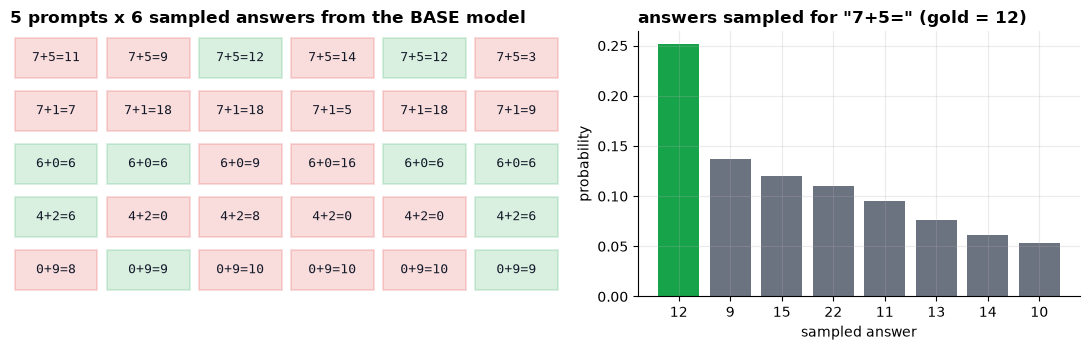

In [6]:
FILM_PROMPTS = [p for p, _ in TEST[:5]]                     # fixed prompts used in every animation

def sample_grid(model, prompts, k=6):
    """Sample k answers for each prompt -> rows of (text, is_correct) for drawing."""
    probs = [(p, GOLD[p]) for p in prompts]
    seq, ok, _ = sample_answers(model, probs, k)
    rows = []
    for i, p in enumerate(prompts):
        row = []
        for j in range(k):
            s = seq[i * k + j]
            row.append((p + tok.decode(s[P:]), bool(ok[i * k + j])))
        rows.append(row)
    return rows

def draw_chips(ax, grid, title=""):
    ncols, nrows = len(grid[0]), len(grid)
    ax.set_xlim(0, ncols); ax.set_ylim(0, nrows); ax.axis("off"); ax.set_title(title, loc="left")
    for r, row in enumerate(grid):
        for c, (text, ok) in enumerate(row):
            colour = COLORS["reward"] if ok else COLORS["penalty"]
            ax.add_patch(plt.Rectangle((c + 0.05, nrows - 1 - r + 0.12), 0.9, 0.76, fc=colour, alpha=0.16, ec=colour, lw=1.4))
            ax.text(c + 0.5, nrows - 1 - r + 0.5, text, ha="center", va="center", fontsize=9, family="monospace", color=COLORS["ink"])

torch.manual_seed(3)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.25, 1]})
draw_chips(ax1, sample_grid(base, FILM_PROMPTS), "5 prompts x 6 sampled answers from the BASE model")

# what the model believes about ONE prompt: the distribution of its sampled answers
seq, ok, _ = sample_answers(base, [("7+5=", "12")], 600)
answers = [tok.decode(s[P:]) for s in seq]
vals, counts = np.unique(answers, return_counts=True); order = np.argsort(-counts)
ax2.bar([vals[i] for i in order][:8], [counts[i] / 600 for i in order][:8],
        color=[COLORS["reward"] if vals[i] == "12" else COLORS["reference"] for i in order][:8])
ax2.set_title('answers sampled for "7+5=" (gold = 12)', loc="left"); ax2.set_ylabel("probability"); ax2.set_xlabel("sampled answer")
plt.tight_layout(); plt.show()

**Read it.** The correct answer is the most common single answer (green bar) but at only ~30% - the rest of the probability is smeared over near-misses. **Post-training will not teach the model arithmetic; it will teach it to *commit* to what it already half-knows.** Different methods do that with different signals - that is the whole story.

## 3. Supervised fine-tuning (SFT): learn by imitation

**Idea.** Show the model prompts with the *correct* answer and train it to predict those tokens. It is exactly the pre-training loss, with two differences: the data are *curated demonstrations*, and the loss is computed **only on the answer** (we do not want to train the model to predict the user's question):

$$\mathcal L_{\text{SFT}}(\theta)=-\frac{1}{|y|}\sum_{t=1}^{|y|}\log\pi_\theta\big(y_t^\star\mid x,\,y^\star_{<t}\big)\qquad\text{($y^\star$ = the demonstrated answer)}$$

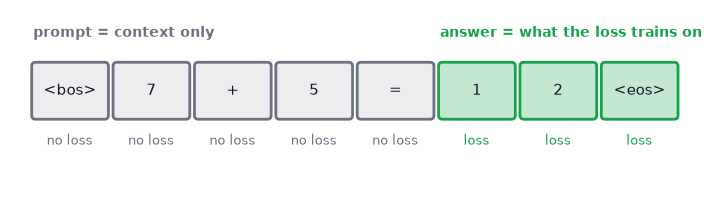

In [7]:
# --- a diagram of what the loss looks at (prompt tokens are context, answer tokens are the targets) ---
fig, ax = plt.subplots(figsize=(9, 2.3)); ax.axis("off"); ax.set_xlim(0, 9); ax.set_ylim(0, 2.3)
toks = ["<bos>", "7", "+", "5", "=", "1", "2", "<eos>"]
for i, t in enumerate(toks):
    is_ans = i >= P
    c = COLORS["reward"] if is_ans else COLORS["reference"]
    draw_box(ax, (0.3 + i * 1.05, 0.9), 0.95, 0.7, t, c, fontsize=11, alpha=0.25 if is_ans else 0.12)
    ax.text(0.3 + i * 1.05 + 0.47, 0.55, "loss" if is_ans else "no loss", ha="center", fontsize=9, color=c)
ax.text(0.3, 1.95, "prompt = context only", color=COLORS["reference"], fontsize=10, weight="bold")
ax.text(0.3 + P * 1.05, 1.95, "answer = what the loss trains on", color=COLORS["reward"], fontsize=10, weight="bold")
plt.savefig(asset_path("pt_sft_mask.png"), bbox_inches="tight", dpi=110); plt.show()

**Check the loss is what the formula says.** `lm_loss` (cross-entropy on answer tokens) must equal "minus the mean log-probability of the demonstrated answer tokens", computed independently from `sequence_logprobs`:

In [8]:
demo = task.sft_batch(16, TRAIN)                                    # "prompt + gold answer + <eos>", padded
mask = response_mask(demo)
manual = -(sequence_logprobs(base, demo) * mask).sum() / mask.sum()  # -mean log pi over answer tokens
print(f"lm_loss {lm_loss(base, demo).item():.5f}   manual {manual.item():.5f}")
verify("3 SFT", "SFT loss = -mean log pi(answer tokens | prompt), prompt excluded", abs(lm_loss(base, demo).item() - manual.item()) < 1e-5)

lm_loss 0.50280   manual 0.50280
PASS | SFT loss = -mean log pi(answer tokens | prompt), prompt excluded 


### SFT in action - watch the probabilities move

We train on the 70 clean demonstrations and, every few steps, read the model's probability for the **first** and **second** answer digit of `7+5=` (gold: `1` then `2`). Gold in green.


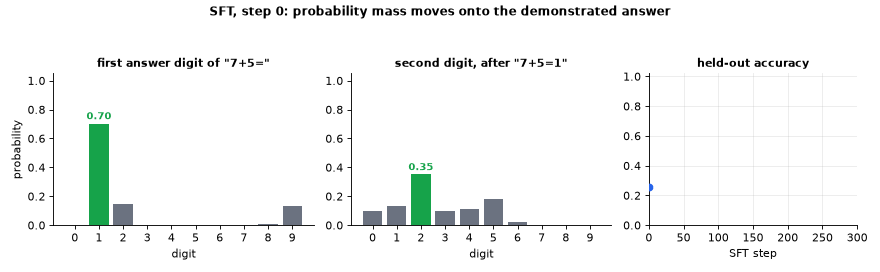

SFT on 70 demos: held-out sampled accuracy 1.00  (base was 0.29)


In [9]:
def digit_probs(model, prefix_text, digits="0123456789"):
    """Next-token probability over the digit tokens after `prefix_text`."""
    with torch.no_grad():
        logits, _ = model(torch.tensor([tok.encode(prefix_text)]))
        probs = F.softmax(logits[0, -1], -1)
    return [probs[tok.stoi[d]].item() for d in digits]

def run_sft(demos, steps=300, lr=1e-3, batch=64, snap_every=0, seed=0):
    """SFT on `demos` (list of (prompt, answer)); optionally snapshot digit probabilities for the film."""
    torch.manual_seed(seed); model = load_base(); opt = torch.optim.AdamW(model.parameters(), lr=lr)
    snaps, losses = [], []
    for step in range(steps + 1):
        if snap_every and step % snap_every == 0:
            snaps.append((step, digit_probs(model, "7+5="), digit_probs(model, "7+5=1"), accuracy(model, TEST, 8)))
        if step == steps: break
        loss = lm_loss(model, task.sft_batch(batch, demos)); opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
    return model, snaps, losses

sft70, snaps, sft_losses = run_sft(TRAIN, steps=300, snap_every=10)

def draw_sft(fig, i):
    step, p1, p2, acc = snaps[i]
    fig.clf(); axs = fig.subplots(1, 3, gridspec_kw={"width_ratios": [1, 1, 0.8]})
    for ax, p, gold, ttl in ((axs[0], p1, 1, 'first answer digit of "7+5="'), (axs[1], p2, 2, 'second digit, after "7+5=1"')):
        ax.bar(range(10), p, color=[COLORS["reward"] if d == gold else COLORS["reference"] for d in range(10)])
        ax.set_ylim(0, 1.05); ax.set_xticks(range(10)); ax.set_title(ttl, fontsize=10); ax.set_xlabel("digit"); ax.grid(False)
        ax.text(gold, p[gold] + 0.03, f"{p[gold]:.2f}", ha="center", fontsize=9, color=COLORS["reward"], weight="bold")
    axs[0].set_ylabel("probability")
    steps = [s[0] for s in snaps[: i + 1]]; accs = [s[3] for s in snaps[: i + 1]]
    axs[2].plot(steps, accs, color=COLORS["policy"], lw=2.5); axs[2].scatter(steps[-1:], accs[-1:], color=COLORS["policy"], zorder=3)
    axs[2].set_xlim(0, snaps[-1][0]); axs[2].set_ylim(0, 1.02); axs[2].set_title("held-out accuracy", fontsize=10); axs[2].set_xlabel("SFT step")
    fig.suptitle(f"SFT, step {step}: probability mass moves onto the demonstrated answer", fontsize=11, weight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.92))

Animator(draw_sft, n_frames=len(snaps), figsize=(11, 3.4), fps=4).save("pt_sft_film.gif")
print(f"SFT on 70 demos: held-out sampled accuracy {accuracy(sft70, TEST):.2f}  (base was {acc_te:.2f})")

**Read it.** Before training the digit probabilities are spread out; by step ~30 nearly all the mass sits on the demonstrated digits and the held-out accuracy (right panel, *never-seen prompts*) climbs with it. SFT is simple, stable and cheap - **but it needs the correct answer for every training prompt**. How much does it matter how many demonstrations you have?

SFT with 10 demonstrations | accuracy on the prompts it saw 0.66 | on NEW prompts 0.52


SFT with 25 demonstrations | accuracy on the prompts it saw 0.76 | on NEW prompts 0.68


SFT with 70 demonstrations | accuracy on the prompts it saw 1.00 | on NEW prompts 1.00


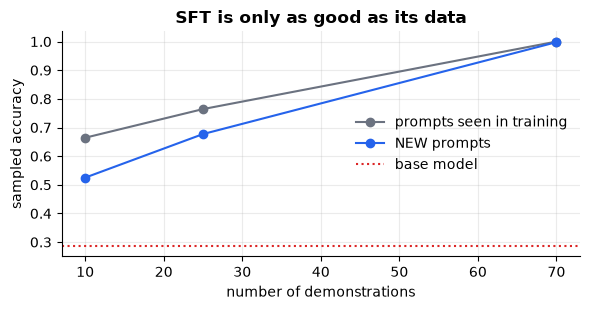

PASS | SFT improves over the base model and more demonstrations help | test acc 0.29 -> 0.52 -> 0.68 -> 1.00


In [10]:
rows = []
for n in (10, 25, 70):
    m, _, _ = run_sft(TRAIN[:n], steps=300)
    rows.append((n, accuracy(m, TRAIN), accuracy(m, TEST)))
    print(f"SFT with {n:2d} demonstrations | accuracy on the prompts it saw {rows[-1][1]:.2f} | on NEW prompts {rows[-1][2]:.2f}")
SFT_BY_N = {n: te for n, _, te in rows}
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot([r[0] for r in rows], [r[1] for r in rows], "o-", color=COLORS["reference"], label="prompts seen in training")
ax.plot([r[0] for r in rows], [r[2] for r in rows], "o-", color=COLORS["policy"], label="NEW prompts")
ax.axhline(acc_te, color=COLORS["penalty"], ls=":", label="base model"); ax.set_xlabel("number of demonstrations"); ax.set_ylabel("sampled accuracy"); ax.legend(); ax.set_title("SFT is only as good as its data")
plt.tight_layout(); plt.show()
verify("3 SFT", "SFT improves over the base model and more demonstrations help", SFT_BY_N[70] > SFT_BY_N[25] > SFT_BY_N[10] > acc_te,
       f"test acc {acc_te:.2f} -> {SFT_BY_N[10]:.2f} -> {SFT_BY_N[25]:.2f} -> {SFT_BY_N[70]:.2f}")

**What SFT cannot do.** It only ever sees *positive* examples: it learns what to imitate, never what to avoid; it cannot exceed its demonstrations; and the demonstrations are costly. The next sections use **feedback on the model's own answers** instead.

## 4. Where does the learning signal come from? Two kinds of reward

SFT needs the right *answer*. Reinforcement learning needs only a **score for an answer the model produced itself**: a reward $R(x,y)$. Where that number comes from is the main design choice in modern post-training:

| | learned reward model (RLHF) | verifiable reward (RLVR) |
|---|---|---|
| source | a neural net trained on human **preferences** | a **program** that checks the answer |
| works for | anything people can compare ("which reply is better?") | things with a checkable answer: maths, code, formats |
| weakness | imperfect, and a strong optimiser *exploits* its mistakes | needs a checker; silent on style/safety |

### 4a. Preferences and the Bradley-Terry reward model

Asking a person to *write* a perfect answer is hard; asking which of two answers is **better** is easy. We collect pairs $(y_w \succ y_l)$ - winner and loser for the same prompt. To turn them into a number we assume the **Bradley-Terry** model: the probability that $y_w$ wins is

$$P(y_w\succ y_l\mid x)=\sigma\big(r_\phi(x,y_w)-r_\phi(x,y_l)\big),\qquad \sigma(z)=\tfrac{1}{1+e^{-z}},$$

and the reward model $r_\phi$ (a transformer with a scalar head) is trained by maximum likelihood:

$$\mathcal L_{\text{RM}}(\phi)=-\mathbb E\big[\log\sigma\big(r_\phi(x,y_w)-r_\phi(x,y_l)\big)\big].$$

Only the *difference* matters, so the reward has no absolute scale. Check the loss on hand numbers before trusting it:

In [11]:
def bt_loss(r_w, r_l):
    return -F.logsigmoid(r_w - r_l)

verify("4 RM", "tie (r_w = r_l) costs exactly log 2", abs(bt_loss(torch.tensor(1.0), torch.tensor(1.0)).item() - math.log(2)) < 1e-6)
verify("4 RM", "a confident correct ranking is nearly free; a confident wrong one is expensive",
       bt_loss(torch.tensor(3.0), torch.tensor(0.0)).item() < 0.05 and bt_loss(torch.tensor(0.0), torch.tensor(3.0)).item() > 3.0,
       f"margin +3: {bt_loss(torch.tensor(3.0), torch.tensor(0.0)).item():.3f}  margin -3: {bt_loss(torch.tensor(0.0), torch.tensor(3.0)).item():.3f}")

PASS | tie (r_w = r_l) costs exactly log 2 
PASS | a confident correct ranking is nearly free; a confident wrong one is expensive | margin +3: 0.049  margin -3: 3.049


**Collecting preference data.** For each prompt we sample 8 answers from the *base* model and pair one correct with one wrong answer. A human labeler is imperfect, so we **flip 10% of the labels** (noise a real pipeline always has):

In [12]:
L_SEQ = P + 4                                                      # every sequence padded to the same length

def pad_to(seq, length=L_SEQ):
    return F.pad(seq, (0, length - seq.shape[-1]), value=tok.PAD)

def make_pairs(model, probs, k=8, flip=0.1, seed=0):
    """Preference pairs (chosen, rejected) of full sequences. Labeler: prefers the correct answer, wrong `flip` of the time."""
    rng = random.Random(seed); pairs = []
    for p, a in probs:
        seq, ok, _ = sample_answers(model, [(p, a)], k)
        good = [i for i in range(k) if ok[i] == 1]; bad = [i for i in range(k) if ok[i] == 0]
        if good and bad:
            c, r = pad_to(seq[rng.choice(good)]), pad_to(seq[rng.choice(bad)])
            if rng.random() < flip: c, r = r, c
            pairs.append((c, r))
    return pairs

torch.manual_seed(11)
base_ref = load_base(trainable=False)
rm_pairs = make_pairs(base_ref, TRAIN * 20, seed=1)
print(f"{len(rm_pairs)} preference pairs, e.g.:")
for c, r in rm_pairs[:3]:
    print("  prefers", repr(tok.decode(c[:P].tolist()) + tok.decode(c[P:])), " over ", repr(tok.decode(r[:P].tolist()) + tok.decode(r[P:])))

1309 preference pairs, e.g.:
  prefers '2+3=5'  over  '2+3=9'
  prefers '0+8=8'  over  '0+8=10'
  prefers '0+7=7'  over  '0+7=5'


**The reward model** is the base transformer with one extra linear layer that reads the hidden state at the **last token** of the answer (`<eos>`) and outputs a single number.

In [13]:
class RewardModel(nn.Module):
    """Transformer trunk (initialised from the base model) + scalar head read at the final answer token."""
    def __init__(self, base_model):
        super().__init__()
        self.trunk = copy.deepcopy(base_model); self.head = ValueHead(base_model.cfg.d_model)
        for p in self.trunk.parameters(): p.requires_grad_(True)
    def forward(self, seq):
        _, hidden = self.trunk(seq)
        last = (seq != tok.PAD).sum(1) - 1                          # index of <eos>
        return self.head(hidden)[torch.arange(len(seq)), last]

def train_reward_model(pairs, steps=800, lr=1e-4, batch=32, seed=0):
    torch.manual_seed(seed); rng = random.Random(seed)
    rm = RewardModel(load_base()); opt = torch.optim.AdamW(rm.parameters(), lr=lr); hist = []
    for _ in range(steps):
        b = [rng.choice(pairs) for _ in range(batch)]
        chosen, rejected = torch.stack([x[0] for x in b]), torch.stack([x[1] for x in b])
        loss = bt_loss(rm(chosen), rm(rejected)).mean(); opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
    return rm.eval(), hist

rm, rm_hist = train_reward_model(rm_pairs)
for p in rm.parameters(): p.requires_grad_(False)
print(f"RM training loss: {np.mean(rm_hist[:20]):.3f} -> {np.mean(rm_hist[-50:]):.3f}   (starts at log 2 = {math.log(2):.3f})")

RM training loss: 0.693 -> 0.356   (starts at log 2 = 0.693)


**Is the reward model any good?** Test it on **prompts it never saw**, with *clean* labels (sampled answers from the base model, scored by the true checker):

held-out prompts: mean score correct 0.21 vs wrong -0.66 | ranking accuracy (AUC) 0.67


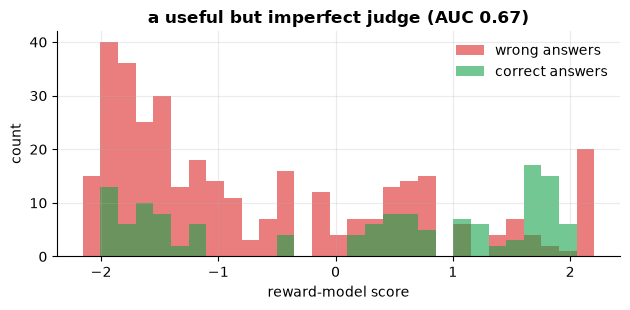

wrong answers that the judge scores ABOVE the median correct answer: 21.2%  <- loopholes a strong optimiser can find
PASS | the reward model ranks correct above wrong answers on unseen prompts (AUC > 0.65) | AUC 0.67
PASS | ...yet some wrong answers get top marks (loopholes exist) | 21.2% of wrong answers beat the median correct one
PASS | ...but it is far from a perfect judge (AUC < 0.97) - keep this in mind for section 6 | AUC 0.67


In [14]:
@torch.no_grad()
def rm_scores_on(probs, k=16):
    seq, ok, _ = sample_answers(base_ref, probs, k)
    return rm(seq), ok

scores, ok = rm_scores_on(TEST)
good, bad = scores[ok == 1], scores[ok == 0]
auc = (good[:, None] > bad[None, :]).float().mean().item()        # P(random correct answer outranks a random wrong one)
print(f"held-out prompts: mean score correct {good.mean():.2f} vs wrong {bad.mean():.2f} | ranking accuracy (AUC) {auc:.2f}")

fig, ax = plt.subplots(figsize=(6.4, 3.2))
bins = np.linspace(scores.min().item(), scores.max().item(), 30)
ax.hist(bad.numpy(), bins, color=COLORS["penalty"], alpha=0.6, label="wrong answers"); ax.hist(good.numpy(), bins, color=COLORS["reward"], alpha=0.6, label="correct answers")
ax.set_xlabel("reward-model score"); ax.set_ylabel("count"); ax.legend(); ax.set_title(f"a useful but imperfect judge (AUC {auc:.2f})")
plt.tight_layout(); plt.show()
median_good = good.median().item(); loopholes = (bad > median_good).float().mean().item()
print(f"wrong answers that the judge scores ABOVE the median correct answer: {loopholes:.1%}  <- loopholes a strong optimiser can find")
verify("4 RM", "the reward model ranks correct above wrong answers on unseen prompts (AUC > 0.65)", auc > 0.65, f"AUC {auc:.2f}")
verify("4 RM", "...yet some wrong answers get top marks (loopholes exist)", loopholes > 0.03, f"{loopholes:.1%} of wrong answers beat the median correct one")
verify("4 RM", "...but it is far from a perfect judge (AUC < 0.97) - keep this in mind for section 6", auc < 0.97, f"AUC {auc:.2f}")

### 4b. The verifiable reward: a program

For maths, code or exact formats we can skip the learned judge entirely. The **verifier** just runs a check - here, exact match:

In [15]:
def verifier_reward(seq, prompts_text=None):
    """1.0 if the decoded answer equals the gold answer, else 0.0 (exact match; cannot be fooled by style)."""
    out = []
    for s in seq.tolist():
        prompt = tok.decode(s[:P]); out.append(float(tok.decode(s[P:]) == GOLD[prompt]))
    return torch.tensor(out)

seq, ok, _ = sample_answers(base_ref, TEST, 4)
verify("4 verifier", "the verifier agrees with the task's own exact-match reward", torch.equal(verifier_reward(seq), ok))

PASS | the verifier agrees with the task's own exact-match reward 


Setting **RLVR** (RL with verifiable rewards) apart from RLHF is exactly this swap: *no reward model to train, nothing to exploit*. Hold that thought - first we need the RL machinery itself.

## 5. The RL objective, in one page

Whatever the reward, post-training RL maximises

$$J(\theta)\;=\;\mathbb E_{x\sim\mathcal D,\;y\sim\pi_\theta(\cdot|x)}\big[R(x,y)\big]\;-\;\beta\;\mathrm{KL}\big(\pi_\theta(\cdot|x)\,\|\,\pi_{\text{ref}}(\cdot|x)\big).$$

- **First term:** get a high reward on your own samples.
- **Second term - the KL "leash":** do not drift far from the *reference* model $\pi_{\text{ref}}$ (the frozen starting point). Without it the model finds weird outputs that fool the reward. $\beta$ is the leash length.

**The policy-gradient trick.** We cannot differentiate through *sampling* a token, but we can use $\nabla_\theta\pi=\pi\,\nabla_\theta\log\pi$:

$$\nabla_\theta\,\mathbb E_{y\sim\pi_\theta}[R]=\mathbb E_{y\sim\pi_\theta}\big[\,R(y)\,\nabla_\theta\log\pi_\theta(y)\,\big]\quad\Longrightarrow\quad\nabla_\theta J\approx\frac1N\sum_i \big(R_i-b\big)\,\nabla_\theta\log\pi_\theta(y_i).$$

"Raise the log-probability of answers in proportion to how good they were." Subtracting a **baseline** $b$ (anything not depending on the sampled answer) leaves the expected gradient unchanged but removes noise. **Every algorithm below (PPO, GRPO, ...) is this formula plus a different choice of baseline and a safety clip.** Verify on a case with an exact answer - four possible outputs:

In [16]:
torch.manual_seed(0)
logits = torch.tensor([0.3, -0.5, 1.0, 0.1], requires_grad=True)         # a policy over 4 "answers"
R = torch.tensor([0.0, 1.0, 0.5, 2.0])                                    # their rewards
pi = F.softmax(logits, 0)
(pi * R).sum().backward(); exact = logits.grad.clone()                    # the true gradient of E[R]

y = torch.multinomial(pi.detach(), 400_000, replacement=True)            # sample many answers
score = F.one_hot(y, 4).float() - pi.detach()                             # grad_logits log pi(y) = onehot(y) - pi
g_plain = R[y][:, None] * score
b = (pi.detach() * R).sum()                                               # baseline = average reward
g_base = (R[y] - b)[:, None] * score
print("exact gradient        ", exact.numpy().round(3))
print("REINFORCE estimate    ", g_plain.mean(0).numpy().round(3), " noise (variance):", round(g_plain.var(0).sum().item(), 3))
print("... with a baseline   ", g_base.mean(0).numpy().round(3), " noise (variance):", round(g_base.var(0).sum().item(), 3))
verify("5 PG", "the policy-gradient estimate matches the exact gradient", (g_plain.mean(0) - exact).abs().max() < 0.02)
verify("5 PG", "a baseline keeps the same gradient with less noise", (g_base.mean(0) - exact).abs().max() < 0.02 and g_base.var(0).sum() < g_plain.var(0).sum())

exact gradient         [-0.169  0.029 -0.105  0.244]
REINFORCE estimate     [-0.168  0.028 -0.103  0.243]  noise (variance): 0.779
... with a baseline    [-0.169  0.029 -0.104  0.244]  noise (variance): 0.316
PASS | the policy-gradient estimate matches the exact gradient 
PASS | a baseline keeps the same gradient with less noise 


**The leash has a closed-form answer.** For a single decision, maximising $\mathbb E_\pi[R]-\beta\,\mathrm{KL}(\pi\|\pi_{\text{ref}})$ has the exact solution

$$\boxed{\;\pi^\star(y)\;=\;\frac{1}{Z}\,\pi_{\text{ref}}(y)\,\exp\!\big(R(y)/\beta\big)\;}$$

("reweight the reference by $e^{R/\beta}$"). Gradient ascent on the objective should land on exactly this - and this identity is what makes **DPO** possible in section 7:

In [17]:
torch.manual_seed(1)
ref_logits = torch.tensor([0.2, -0.3, 0.5, 0.0, -0.6]); R5 = torch.tensor([0.0, 1.0, 0.2, 2.0, -1.0]); beta = 0.7
theta = ref_logits.clone().requires_grad_(True); opt = torch.optim.Adam([theta], lr=0.05)
pi_ref = F.softmax(ref_logits, 0)
for _ in range(4000):
    pi = F.softmax(theta, 0)
    J = (pi * R5).sum() - beta * (pi * (pi.log() - pi_ref.log())).sum()      # reward - beta * KL
    opt.zero_grad(); (-J).backward(); opt.step()
pi_star = pi_ref * torch.exp(R5 / beta); pi_star = pi_star / pi_star.sum()
print("gradient ascent:", F.softmax(theta, 0).detach().numpy().round(4)); print("closed form    :", pi_star.numpy().round(4))
verify("5 objective", "maximising reward - beta*KL lands on pi* = pi_ref * exp(R/beta) / Z", (F.softmax(theta, 0).detach() - pi_star).abs().max() < 1e-3)
PI_REF5, PI_STAR5, R5_, BETA5 = pi_ref, pi_star, R5, beta                   # reused by the DPO section

gradient ascent: [0.0508 0.1285 0.0912 0.724  0.0055]
closed form    : [0.0508 0.1285 0.0912 0.724  0.0055]
PASS | maximising reward - beta*KL lands on pi* = pi_ref * exp(R/beta) / Z 


## 6. RLHF with PPO: the original recipe

**Proximal Policy Optimization** (PPO, Schulman et al., 2017) is the RL algorithm InstructGPT used. For language models it runs **four models**:

| model | role | trained? |
|---|---|---|
| **policy** $\pi_\theta$ | writes answers | yes |
| **reference** $\pi_{\text{ref}}$ | the frozen starting point for the KL leash | no |
| **reward model** | scores a finished answer | no |
| **critic** $V_\phi$ | predicts the reward-to-go from each token (reduces noise) | yes |

![PPO vs GRPO](../../assets/rl/course/paper_deepseekmath_fig4_ppo_vs_grpo.png)

**DeepSeekMath (Shao et al., 2024), Fig. 4 (PDF p. 13):** "Demonstration of PPO and our GRPO. GRPO foregoes the value model, instead estimating the baseline from group scores, significantly reducing training resources."

*What to look for:* the top row is what we build in this section (policy, reference, reward, value model, GAE); the bottom row is section 8.

### 6a. The reward the policy actually optimises

The reward model scores only the *finished* answer, but PPO wants credit for every *token*. So each answer token gets the KL penalty, and the final token also gets the reward-model score:

$$r_t \;=\; -\beta\,\big[\log\pi_\theta(y_t|x,y_{<t})-\log\pi_{\text{ref}}(y_t|x,y_{<t})\big]\;+\;\mathbb 1[t=\text{last}]\cdot r_\phi(x,y).$$

### 6b. Advantages with GAE

The **advantage** $A_t$ says "was this token better or worse than the critic expected?". **Generalised advantage estimation** blends one-step and full-return estimates with $\lambda$:

$$\delta_t=r_t+\gamma V_{t+1}-V_t,\qquad A_t=\sum_{l\ge0}(\gamma\lambda)^l\,\delta_{t+l}.$$

$\lambda=0$ trusts the critic (low noise, some bias); $\lambda=1$ ignores it (the plain reward-to-go). Check both ends:

In [18]:
def gae(rewards, values, mask, gamma=1.0, lam=0.95):
    """Generalised advantage estimation over answer positions. rewards/values/mask: (B, T)."""
    B, T = rewards.shape
    adv, last = torch.zeros_like(rewards), torch.zeros(B)
    for t in reversed(range(T)):
        nonterminal = mask[:, t + 1] if t + 1 < T else torch.zeros(B)           # is there a next answer token?
        next_v = values[:, t + 1] * nonterminal if t + 1 < T else torch.zeros(B)
        delta = rewards[:, t] + gamma * next_v - values[:, t]
        last = delta + gamma * lam * nonterminal * last
        adv[:, t] = last * mask[:, t]
    return adv

r_ = torch.tensor([[0.0, 0.0, 1.0]]); v_ = torch.tensor([[0.2, 0.4, 0.6]]); m_ = torch.ones(1, 3)
reward_to_go = torch.tensor([[1.0, 1.0, 1.0]]) - v_                              # with gamma=1: sum of future rewards minus V
verify("6 GAE", "lambda=1 gives reward-to-go minus the critic's value", torch.allclose(gae(r_, v_, m_, 1.0, 1.0), reward_to_go, atol=1e-6), f"{gae(r_, v_, m_, 1.0, 1.0).numpy().round(2)}")
td = r_ + torch.cat([v_[:, 1:], torch.zeros(1, 1)], 1) - v_
verify("6 GAE", "lambda=0 gives the one-step TD error", torch.allclose(gae(r_, v_, m_, 1.0, 0.0), td, atol=1e-6), f"{gae(r_, v_, m_, 1.0, 0.0).numpy().round(2)}")

PASS | lambda=1 gives reward-to-go minus the critic's value | [[0.8 0.6 0.4]]
PASS | lambda=0 gives the one-step TD error | [[0.2 0.2 0.4]]


### 6c. The clipped objective - "proximal" means "do not move too far"

Reusing the same sampled answers for several gradient steps is cheaper, but the policy moves away from the one that *produced* the samples. PPO measures the move with the probability ratio $\rho_t=\pi_\theta/\pi_{\theta_{\text{old}}}$ and **clips** it:

$$L^{\text{clip}}=\mathbb E_t\big[\min\big(\rho_t A_t,\;\operatorname{clip}(\rho_t,1-\epsilon,1+\epsilon)\,A_t\big)\big].$$

Read it case by case ($\epsilon=0.2$): a good token ($A>0$) stops earning extra credit once $\rho>1.2$; a bad token ($A<0$) stops being pushed down once $\rho<0.8$ - but a *wrong-direction* move is never clipped away.

In [19]:
def ppo_clip_objective(ratio, adv, eps=0.2):
    return torch.min(ratio * adv, ratio.clamp(1 - eps, 1 + eps) * adv)

cases = [("good token, ratio 1.5 (already up a lot)", 1.5, +1.0, 1.2), ("good token, ratio 0.5 (moved the wrong way)", 0.5, +1.0, 0.5),
         ("bad token,  ratio 0.5 (already down a lot)", 0.5, -1.0, -0.8), ("bad token,  ratio 1.5 (moved the wrong way)", 1.5, -1.0, -1.5)]
for name, rho, A, expected in cases:
    got = ppo_clip_objective(torch.tensor(rho), torch.tensor(A)).item()
    print(f"{name:48s} objective {got:+.2f}   (expected {expected:+.2f})")
    assert abs(got - expected) < 1e-6
verify("6 PPO", "the clipped objective behaves as the four-case table says", True)

good token, ratio 1.5 (already up a lot)         objective +1.20   (expected +1.20)
good token, ratio 0.5 (moved the wrong way)      objective +0.50   (expected +0.50)
bad token,  ratio 0.5 (already down a lot)       objective -0.80   (expected -0.80)
bad token,  ratio 1.5 (moved the wrong way)      objective -1.50   (expected -1.50)
PASS | the clipped objective behaves as the four-case table says 


### 6d. The whole loop

In [20]:
def ppo_rlhf(policy, ref, reward_fn, iters=300, n_prompts=128, lr=1e-4, beta=0.05, eps=0.2, epochs=3,
             gamma=1.0, lam=0.95, seed=0, callback=None):
    """RLHF-style PPO. `reward_fn(seq) -> (B,)` is the learned reward model (or, in section 9, the verifier)."""
    rng = random.Random(seed)
    critic = load_base(); vhead = ValueHead(policy.cfg.d_model)                  # the 4th model: a value function
    opt = torch.optim.AdamW(policy.parameters(), lr=lr)
    copt = torch.optim.AdamW(list(critic.parameters()) + list(vhead.parameters()), lr=1e-4)
    hist, info = [], None
    for it in range(iters):
        if callback: callback(it, policy, info)                                              # records the state BEFORE this update
        probs = [rng.choice(TRAIN) for _ in range(n_prompts)]
        seq, correct, _ = sample_answers(policy, probs, 1); mask = response_mask(seq)       # 1) roll out
        with torch.no_grad():
            old_logp, ref_logp = sequence_logprobs(policy, seq), sequence_logprobs(ref, seq)
            score = reward_fn(seq)                                                          # 2) score the finished answers
            _, hc = critic(seq); values = torch.zeros_like(old_logp); values[:, 1:] = vhead(hc)[:, :-1]  # V of the state BEFORE token t
            rewards = -beta * (old_logp - ref_logp) * mask                                   # 3) per-token KL penalty ...
            rewards[torch.arange(len(seq)), (seq != tok.PAD).sum(1) - 1] += score           #    ... + score on the last token
            adv = gae(rewards, values, mask, gamma, lam); returns = adv + values             # 4) advantages
            mean = masked_mean(adv, mask); std = (masked_mean((adv - mean) ** 2, mask)).sqrt().clamp(min=1e-6)
            adv = (adv - mean) / std * mask
        for _ in range(epochs):                                                             # 5) a few clipped updates
            new_logp = sequence_logprobs(policy, seq); ratio = torch.exp(new_logp - old_logp)
            loss = -masked_mean(ppo_clip_objective(ratio, adv, eps), mask)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(policy.parameters(), 1.0); opt.step()
            _, hc = critic(seq); v = torch.zeros_like(old_logp); v[:, 1:] = vhead(hc)[:, :-1]
            vloss = masked_mean((v - returns) ** 2, mask); copt.zero_grad(); vloss.backward(); copt.step()
        info = dict(true=correct.mean().item(), score=score.mean().item(), train_kl=((old_logp - ref_logp) * mask).sum(1).mean().item())
        hist.append(info)
    if callback: callback(iters, policy, info)
    return hist

**A sanity check before running it.** Right after sampling, the policy has not moved, so $\rho=1$ and the clip is inactive: the PPO gradient must reduce to the plain "advantage times $\nabla\log\pi$" policy gradient. Then we run it with the *learned* reward model.

In [21]:
lp = torch.randn(6, requires_grad=True); adv_ = torch.randn(6)
ratio_ = torch.exp(lp - lp.detach())                                  # == 1 in value, but carries the gradient of log pi
ppo_clip_objective(ratio_, adv_).sum().backward()
verify("6 PPO", "at ratio 1 the PPO gradient equals advantage x grad log-prob (plain policy gradient)", torch.allclose(lp.grad, adv_, atol=1e-6))

PASS | at ratio 1 the PPO gradient equals advantage x grad log-prob (plain policy gradient) 


PPO with the learned reward model: 8s
held-out accuracy 0.29 -> 0.60   |  reward-model score -0.14 -> 1.25



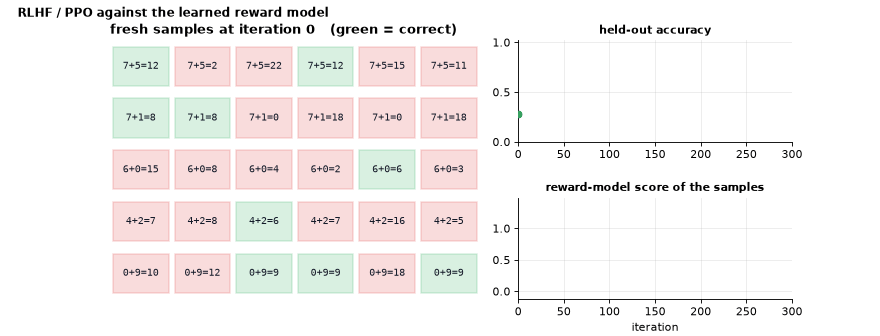

In [22]:
class Tracker:
    """Every `every` iterations record: held-out accuracy, KL from the base model, a fixed grid of samples (for the films)."""
    def __init__(self, ref, every=10): self.ref, self.every, self.rows = ref, every, []
    def __call__(self, it, policy, info=None):
        if it % self.every: return
        self.rows.append(dict(info or {}, it=it, acc=accuracy(policy, TEST, 16), kl=seq_kl(policy, self.ref, TEST), grid=sample_grid(policy, FILM_PROMPTS)))

def rl_film(tracker, name, title, bottom, fps=4):
    """Animation: left = fresh samples on 5 fixed prompts; right = held-out accuracy and a second curve.
    `bottom` = (key, label, colour) of the second metric taken from each recorded row."""
    key, label, colour = bottom; rows = tracker.rows
    def draw(fig, i):
        fig.clf(); gs = fig.add_gridspec(2, 2, width_ratios=[1.35, 1], hspace=0.55, wspace=0.12)
        draw_chips(fig.add_subplot(gs[:, 0]), rows[i]["grid"], f"fresh samples at iteration {rows[i]['it']}   (green = correct)")
        its = [r["it"] for r in rows[: i + 1]]
        a1, a2 = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])
        a1.plot(its, [r["acc"] for r in rows[: i + 1]], color=COLORS["reward"], lw=2.5); a1.scatter(its[-1:], [rows[i]["acc"]], color=COLORS["reward"], zorder=3)
        a1.set_ylim(0, 1.02); a1.set_xlim(0, rows[-1]["it"]); a1.set_title("held-out accuracy", fontsize=10)
        vals = [r.get(key, np.nan) for r in rows[: i + 1]]; allv = np.array([r.get(key, np.nan) for r in rows], dtype=float)
        lo, hi = np.nanmin(allv), np.nanmax(allv); pad = 0.08 * (hi - lo + 1e-6)
        a2.plot(its, vals, color=colour, lw=2.5); a2.scatter(its[-1:], vals[-1:], color=colour, zorder=3)
        a2.set_xlim(0, rows[-1]["it"]); a2.set_ylim(lo - pad, hi + pad); a2.set_title(label, fontsize=10); a2.set_xlabel("iteration")
        fig.suptitle(title, fontsize=11, weight="bold", x=0.02, ha="left")
    Animator(draw, n_frames=len(rows), figsize=(11, 4.2), fps=fps).save(name)

ref = load_base(trainable=False)
torch.manual_seed(21)
ppo_rm_policy = load_base(); ppo_rm_trk = Tracker(ref)
t0 = time.time(); ppo_rm_hist = ppo_rlhf(ppo_rm_policy, ref, rm, callback=ppo_rm_trk); print(f"PPO with the learned reward model: {time.time() - t0:.0f}s")
print(f"held-out accuracy {acc_te:.2f} -> {ppo_rm_trk.rows[-1]['acc']:.2f}   |  reward-model score {ppo_rm_hist[0]['score']:.2f} -> {np.mean([h['score'] for h in ppo_rm_hist[-20:]]):.2f}")
rl_film(ppo_rm_trk, "pt_ppo_rm_film.gif", "RLHF / PPO against the learned reward model", ("score", "reward-model score of the samples", COLORS["accent"]))

**Read the animation.** Tiles turn greener and held-out accuracy rises - but look at the second curve: the **reward-model score keeps climbing**. And look closely at the *tiles in the last frames*: for some prompts every sample is the **same wrong answer** - the policy found something the reward model likes and committed to it (section 10 counts how often). Does *true* accuracy follow the score?

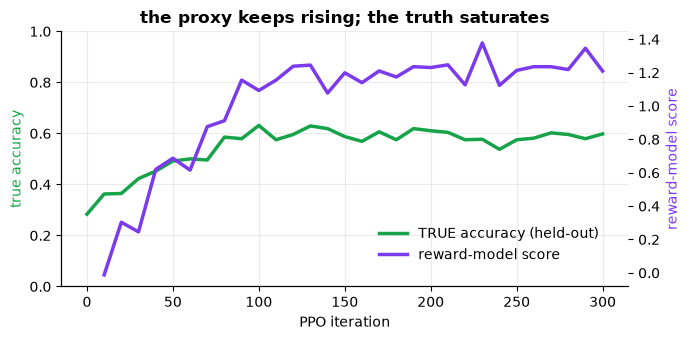

PASS | RLHF with the learned reward improves the model over the base | 0.29 -> 0.59


In [23]:
its = [r["it"] for r in ppo_rm_trk.rows]
fig, ax = plt.subplots(figsize=(7, 3.5)); ax2 = ax.twinx(); ax2.grid(False)
ax.plot(its, [r["acc"] for r in ppo_rm_trk.rows], color=COLORS["reward"], lw=2.5, label="TRUE accuracy (held-out)")
ax2.plot(its, [r.get("score", np.nan) for r in ppo_rm_trk.rows], color=COLORS["accent"], lw=2.5, label="reward-model score")
ax.set_ylim(0, 1); ax.set_xlabel("PPO iteration"); ax.set_ylabel("true accuracy", color=COLORS["reward"]); ax2.set_ylabel("reward-model score", color=COLORS["accent"])
ax.set_title("the proxy keeps rising; the truth saturates"); fig.legend(loc="lower right", bbox_to_anchor=(0.88, 0.2)); plt.tight_layout(); plt.show()
ppo_rm_acc = float(np.mean([r["acc"] for r in ppo_rm_trk.rows[-5:]]))
verify("6 PPO", "RLHF with the learned reward improves the model over the base", ppo_rm_acc > acc_te + 0.1, f"{acc_te:.2f} -> {ppo_rm_acc:.2f}")

**What you are seeing is reward-model over-optimisation (Goodhart's law).** The policy is optimised against the *reward model*, not against the truth. Once it has learned everything the reward model gets right, the remaining gains come from **its mistakes** - the score rises while real quality stalls. Two practical consequences: RLHF is only as good as the reward model, and the **KL leash $\beta$** exists to limit how far the policy can wander into the reward model's blind spots. Try two leash lengths:

In [24]:
rows = []
for beta in (0.05, 0.5):
    torch.manual_seed(31); pol = load_base()
    h = ppo_rlhf(pol, ref, rm, beta=beta, iters=300)
    rows.append((beta, accuracy(pol, TEST), seq_kl(pol, ref, TEST), np.mean([x["score"] for x in h[-20:]])))
    print(f"beta = {beta:4.2f} | held-out accuracy {rows[-1][1]:.2f} | KL from base {rows[-1][2]:5.2f} nats | reward-model score {rows[-1][3]:.2f}")
verify("6 PPO", "a longer leash (smaller beta) lets the policy drift further from the base model", rows[0][2] > rows[1][2], f"KL {rows[0][2]:.2f} vs {rows[1][2]:.2f}")

beta = 0.05 | held-out accuracy 0.65 | KL from base  1.33 nats | reward-model score 1.25


beta = 0.50 | held-out accuracy 0.59 | KL from base  0.66 nats | reward-model score 1.15
PASS | a longer leash (smaller beta) lets the policy drift further from the base model | KL 1.33 vs 0.66


## 7. DPO: RLHF without the reward model and without the RL loop

RLHF has two stages (fit a reward model, then run RL against it), which is where the cost and the instability come from. **Direct Preference Optimization** (Rafailov et al., 2023) observes that the pair of stages can be collapsed into **one supervised-style loss on the preference pairs**.

![DPO vs RLHF](../../assets/rl/course/paper_dpo_fig1.png)

**DPO (Rafailov et al., 2023), Fig. 1 (PDF p. 2):** "DPO optimizes for human preferences while avoiding reinforcement learning. Existing methods for fine-tuning language models with human feedback first fit a reward model to a dataset of prompts and human preferences over pairs of responses, and then use RL to find a policy that maximizes the learned reward. In contrast, DPO directly optimizes for the policy best satisfying the preferences with a simple classification objective [...]"

### The derivation in three lines (and each line is checked)

1. **The RLHF optimum** (section 5): $\;\pi^\star(y|x)=\pi_{\text{ref}}(y|x)\,e^{r(x,y)/\beta}/Z(x)$.
2. **Solve for the reward:** $\;r(x,y)=\beta\log\dfrac{\pi^\star(y|x)}{\pi_{\text{ref}}(y|x)}+\beta\log Z(x)$. *The policy itself encodes a reward.*
3. **Plug into Bradley-Terry.** The preference depends only on a *difference* of rewards, so the awkward $\beta\log Z(x)$ **cancels**, leaving the DPO loss with the policy $\pi_\theta$ in place of $\pi^\star$:

$$\mathcal L_{\text{DPO}}(\theta)=-\mathbb E\Big[\log\sigma\Big(\beta\big[\underbrace{\log\tfrac{\pi_\theta(y_w|x)}{\pi_{\text{ref}}(y_w|x)}}_{\text{chosen: push up}}-\underbrace{\log\tfrac{\pi_\theta(y_l|x)}{\pi_{\text{ref}}(y_l|x)}}_{\text{rejected: push down}}\big]\Big)\Big].$$

Steps 2-3 can be tested with the five-outcome example from section 5, where we know the true rewards:

In [25]:
implicit = BETA5 * (PI_STAR5.log() - PI_REF5.log())                       # step 2 with Z left out: beta * log(pi*/pi_ref)
offset = implicit - R5_
print("implicit reward minus true reward, per outcome:", offset.numpy().round(4), "  (all equal = a constant, beta*log Z)")
verify("7 DPO", "beta*log(pi*/pi_ref) recovers the true reward up to ONE constant (beta log Z)", (offset - offset[0]).abs().max() < 1e-5)
i, j = 3, 1                                                                # any pair of outcomes
p_true, p_implicit = torch.sigmoid(R5_[i] - R5_[j]), torch.sigmoid(implicit[i] - implicit[j])
verify("7 DPO", "so Bradley-Terry preference probabilities are identical (the constant cancels)", abs(p_true - p_implicit) < 1e-6, f"P(i beats j): {p_true:.4f} vs {p_implicit:.4f}")

implicit reward minus true reward, per outcome: [-1.0775 -1.0775 -1.0775 -1.0775 -1.0775]   (all equal = a constant, beta*log Z)
PASS | beta*log(pi*/pi_ref) recovers the true reward up to ONE constant (beta log Z) 
PASS | so Bradley-Terry preference probabilities are identical (the constant cancels) | P(i beats j): 0.7311 vs 0.7311


### The loss in code

The only ingredients are the summed log-probabilities of the chosen and rejected answers under the policy and the frozen reference:

In [26]:
def seq_logp(model, seq):
    """log pi(answer | prompt) for each sequence: sum of token log-probs over the answer tokens."""
    return (sequence_logprobs(model, seq) * response_mask(seq)).sum(-1)

def dpo_loss(pol_c, pol_r, ref_c, ref_r, beta=0.1):
    margin = beta * ((pol_c - ref_c) - (pol_r - ref_r))                    # the "implicit reward" gap
    return -F.logsigmoid(margin), margin

# at the start the policy IS the reference, so every margin is 0 and the loss is exactly log 2
c = torch.tensor([-2.0, -3.1]); r = torch.tensor([-2.5, -1.0])
loss0, margin0 = dpo_loss(c, r, c, r)
verify("7 DPO", "loss = log 2 when the policy equals the reference", torch.allclose(loss0, torch.full((2,), math.log(2))))
# the gradient raises the chosen answer and lowers the rejected one
pc, pr = c.clone().requires_grad_(True), r.clone().requires_grad_(True)
dpo_loss(pc, pr, c, r)[0].sum().backward()
verify("7 DPO", "gradient descent raises log pi(chosen) and lowers log pi(rejected)", bool((pc.grad < 0).all() and (pr.grad > 0).all()), f"d loss/d chosen = {pc.grad.numpy().round(3)}")

PASS | loss = log 2 when the policy equals the reference 
PASS | gradient descent raises log pi(chosen) and lowers log pi(rejected) | d loss/d chosen = [-0.05 -0.05]


### Train it

Same base model, same kind of preference pairs as the reward model used (sampled from the base model, 10% label noise). **No reward model, no sampling during training, no critic** - just a loop over the pairs:

655 preference pairs


DPO trained in 5s
loss 0.693 -> 0.386 | held-out accuracy 0.29 -> 0.74



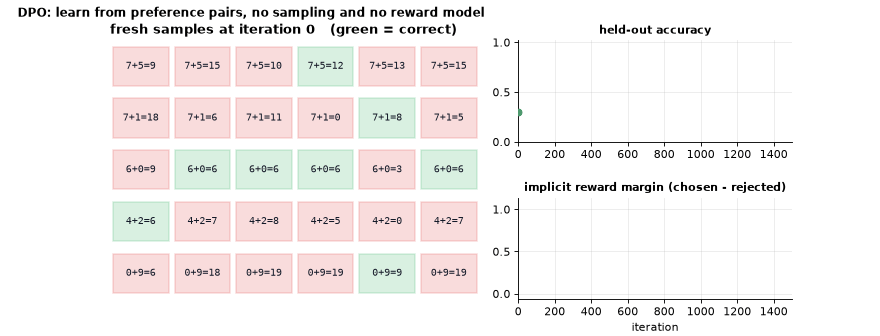

In [27]:
torch.manual_seed(41)
dpo_pairs = make_pairs(base_ref, TRAIN * 10, k=8, flip=0.1, seed=2)
print(len(dpo_pairs), "preference pairs")

def train_dpo(pairs, steps=1500, lr=5e-5, beta=0.1, batch=32, seed=0, callback=None):
    torch.manual_seed(seed); rng = random.Random(seed)
    policy, ref_m = load_base(), load_base(trainable=False)
    chosen_all, rejected_all = torch.stack([p[0] for p in pairs]), torch.stack([p[1] for p in pairs])
    with torch.no_grad(): ref_c_all, ref_r_all = seq_logp(ref_m, chosen_all), seq_logp(ref_m, rejected_all)   # reference never changes: score once
    opt = torch.optim.AdamW(policy.parameters(), lr=lr); hist, info = [], None
    for step in range(steps):
        if callback: callback(step, policy, info)
        idx = torch.tensor([rng.randrange(len(pairs)) for _ in range(batch)])
        pol_c, pol_r = seq_logp(policy, chosen_all[idx]), seq_logp(policy, rejected_all[idx])
        loss, margin = dpo_loss(pol_c, pol_r, ref_c_all[idx], ref_r_all[idx], beta)
        opt.zero_grad(); loss.mean().backward(); opt.step()
        info = dict(loss=loss.mean().item(), margin=margin.mean().item(), pair_acc=(margin > 0).float().mean().item(),
                    d_chosen=(pol_c - ref_c_all[idx]).mean().item(), d_rejected=(pol_r - ref_r_all[idx]).mean().item())
        hist.append(info)
    if callback: callback(steps, policy, info)
    return policy, hist

dpo_trk = Tracker(ref, every=50)
t0 = time.time(); dpo_policy, dpo_hist = train_dpo(dpo_pairs, callback=dpo_trk); print(f"DPO trained in {time.time() - t0:.0f}s")
print(f"loss {dpo_hist[0]['loss']:.3f} -> {np.mean([h['loss'] for h in dpo_hist[-50:]]):.3f} | held-out accuracy {acc_te:.2f} -> {dpo_trk.rows[-1]['acc']:.2f}")
rl_film(dpo_trk, "pt_dpo_film.gif", "DPO: learn from preference pairs, no sampling and no reward model", ("margin", "implicit reward margin (chosen - rejected)", COLORS["accent"]))

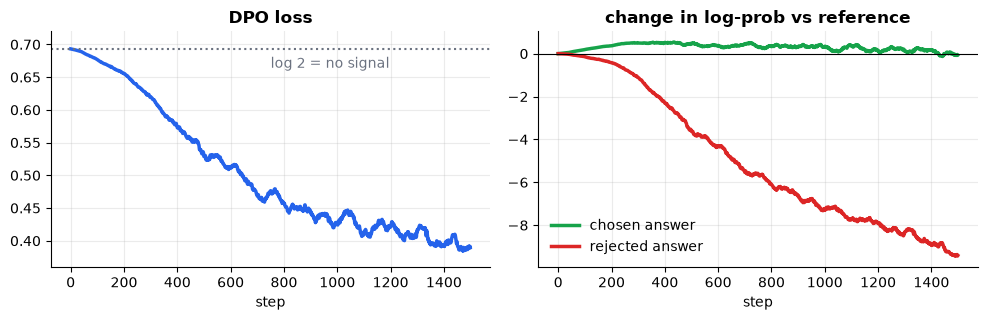

change in log-prob at the end: chosen -0.01   rejected -9.43
PASS | DPO improves held-out accuracy over the base model | 0.29 -> 0.76
PASS | the gap is created mostly by pushing REJECTED answers down (chosen barely moves) | chosen -0.01 vs rejected -9.43


In [28]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.3))
a.plot(smooth([h["loss"] for h in dpo_hist], 40), color=COLORS["policy"], lw=2.5); a.axhline(math.log(2), color=COLORS["reference"], ls=":"); a.text(len(dpo_hist) * 0.5, math.log(2) - 0.012, "log 2 = no signal", color=COLORS["reference"], va="top"); a.set_ylim(0.36, 0.72)
a.set_title("DPO loss"); a.set_xlabel("step")
b.plot(smooth([h["d_chosen"] for h in dpo_hist], 40), color=COLORS["reward"], lw=2.5, label="chosen answer")
b.plot(smooth([h["d_rejected"] for h in dpo_hist], 40), color=COLORS["penalty"], lw=2.5, label="rejected answer"); b.axhline(0, color="k", lw=0.8)
b.set_title("change in log-prob vs reference"); b.set_xlabel("step"); b.legend()
plt.tight_layout(); plt.show()
dpo_acc = float(np.mean([r["acc"] for r in dpo_trk.rows[-3:]]))
d_c, d_r = np.mean([h["d_chosen"] for h in dpo_hist[-50:]]), np.mean([h["d_rejected"] for h in dpo_hist[-50:]])
print(f"change in log-prob at the end: chosen {d_c:+.2f}   rejected {d_r:+.2f}")
verify("7 DPO", "DPO improves held-out accuracy over the base model", dpo_acc > acc_te + 0.1, f"{acc_te:.2f} -> {dpo_acc:.2f}")
verify("7 DPO", "the gap is created mostly by pushing REJECTED answers down (chosen barely moves)", abs(d_r) > 3 * abs(d_c), f"chosen {d_c:+.2f} vs rejected {d_r:+.2f}")

**Read it.** The loss falls from $\log 2$ and the model gets better. The right plot is the thing people find surprising: DPO optimises the **gap** between chosen and rejected - and in this run the chosen answer's log-probability **barely moves** (green, near 0) while the rejected one **plunges** (red). It is a *relative* objective that works mostly by pushing bad answers down, not "make the good answer much more likely" (the check above tests exactly this).

**DPO's honest limits.** (1) It is **offline**: the pairs came from the *base* model and are never refreshed, so the policy never gets feedback on *its own* new answers (the RL methods do). (2) It inherits the labeler's noise. (3) Because it never samples, it cannot tell you "this answer is wrong" for something outside the pairs.

## 8. GRPO: PPO without the critic

PPO's critic is a whole extra network to train and keep in memory. **Group Relative Policy Optimization** (DeepSeekMath, 2024) removes it with a simple idea: if a prompt has *several* answers, **each answer's baseline is the average reward of its own group**.

For each prompt sample $G$ answers $y_1..y_G$, score them, and use

$$\hat A_i=\frac{R_i-\operatorname{mean}(R_1..R_G)}{\operatorname{std}(R_1..R_G)+\varepsilon}\qquad\text{for every token of answer }i.$$

"Was this answer better than its siblings?" is exactly the question a baseline answers, so no learned value function is needed. The update is the *same* clipped PPO objective, plus a small KL term to the reference, estimated per token with the always-positive estimator $k_3=e^{\delta}-\delta-1,\ \delta=\log\pi_{\text{ref}}-\log\pi_\theta$:

$$\mathcal L_{\text{GRPO}}=-\mathbb E\big[\min(\rho_t\hat A_i,\ \operatorname{clip}(\rho_t,1\pm\epsilon)\hat A_i)\;-\;\beta\,k_3\big].$$

**Anatomy of one group** (from the base model, one training prompt, $G=8$):

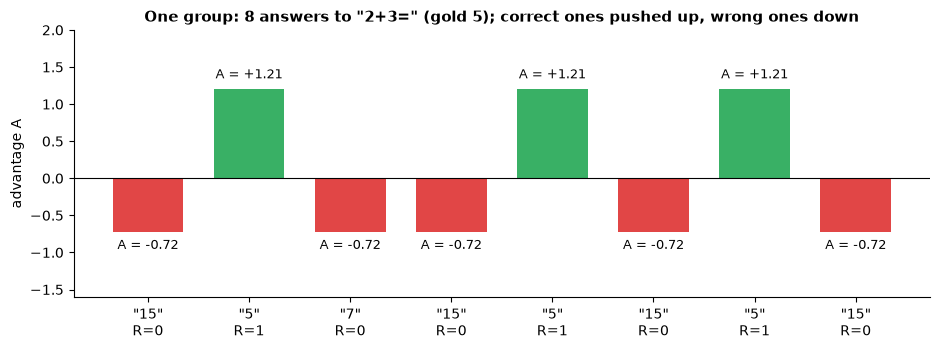

In [29]:
def group_advantages(rewards, group_size, eps=1e-4):
    r = rewards.view(-1, group_size)
    return ((r - r.mean(1, keepdim=True)) / (r.std(1, keepdim=True) + eps)).view(-1)

torch.manual_seed(5)
for prompt, gold in TRAIN:                                         # first prompt whose group is mixed (some right, some wrong)
    seq, ok, _ = sample_answers(base_ref, [(prompt, gold)], 8)
    if 0 < ok.sum() < 8: break
R8 = verifier_reward(seq); A8 = group_advantages(R8, 8)
texts = [tok.decode(s[P:]) for s in seq.tolist()]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
colors = [COLORS["reward"] if a > 0 else (COLORS["penalty"] if a < 0 else COLORS["reference"]) for a in A8.tolist()]
ax.bar(range(8), A8.numpy(), color=colors, alpha=0.85, width=0.7)
for i in range(8):
    ax.text(i, A8[i] + (0.1 if A8[i] >= 0 else -0.1), f"A = {A8[i]:+.2f}", ha="center", va="bottom" if A8[i] >= 0 else "top", fontsize=9)
ax.set_xticks(range(8)); ax.set_xticklabels([f'"{t}"\nR={R8[i]:.0f}' for i, t in enumerate(texts)], fontsize=10)
ax.axhline(0, color="k", lw=0.8); ax.set_ylabel("advantage A"); ax.set_ylim(-1.6, 2.0); ax.grid(False)
ax.set_title(f'One group: 8 answers to "{prompt}" (gold {gold}); correct ones pushed up, wrong ones down', fontsize=11)
plt.tight_layout(); plt.show()

**Check the maths** - group advantages must average to zero (the baseline is the group mean), have unit spread, and vanish when every answer got the same reward:

In [30]:
rng_t = torch.tensor([[1., 0., 0., 1., 0., 0., 0., 1.], [1., 1., 1., 1., 1., 1., 1., 1.], [0.] * 8, [1., 0., 0., 0., 0., 0., 0., 0.]])
adv_t = group_advantages(rng_t.reshape(-1), 8).view(4, 8)
verify("8 GRPO", "advantages average to 0 within each group", adv_t.mean(1).abs().max() < 1e-5)
verify("8 GRPO", "mixed groups have unit standard deviation", abs(adv_t[0].std().item() - 1) < 1e-2 and abs(adv_t[3].std().item() - 1) < 1e-2)
verify("8 GRPO", "all-correct and all-wrong groups give ZERO advantage (no learning signal)", adv_t[1].abs().max() < 1e-3 and adv_t[2].abs().max() < 1e-3)
# k3 is an unbiased estimator of KL(p || q) from samples of p
p, q = F.softmax(torch.tensor([1.0, 0.2, -0.5, 0.3]), 0), F.softmax(torch.tensor([0.4, 0.6, 0.0, -0.2]), 0)
exact_kl = (p * (p / q).log()).sum().item(); s = torch.multinomial(p, 500_000, replacement=True)
k3 = kl_k3(p[s].log(), q[s].log()).mean().item()
verify("8 GRPO", "the k3 estimator is an unbiased KL estimate", abs(k3 - exact_kl) / exact_kl < 0.02, f"exact {exact_kl:.4f}  k3 {k3:.4f}")

PASS | advantages average to 0 within each group 
PASS | mixed groups have unit standard deviation 
PASS | all-correct and all-wrong groups give ZERO advantage (no learning signal) 
PASS | the k3 estimator is an unbiased KL estimate | exact 0.1181  k3 0.1181


**The loop.** It is the PPO loop of section 6 with three deletions: no critic, no GAE, no reward-model-based reward (here the verifier scores each answer):

In [31]:
def grpo(policy, ref, reward_fn, iters=300, n_prompts=16, G=8, lr=3e-4, beta=0.02, eps=0.2, epochs=2,
         seed=0, callback=None, prompts=None):
    """GRPO: 16 prompts x 8 answers = 128 sampled answers per iteration (same budget as the PPO runs)."""
    rng = random.Random(seed); opt = torch.optim.AdamW(policy.parameters(), lr=lr); hist, info = [], None
    pool = prompts or TRAIN
    for it in range(iters):
        if callback: callback(it, policy, info)
        probs = [rng.choice(pool) for _ in range(n_prompts)]
        seq, correct, _ = sample_answers(policy, probs, G); mask = response_mask(seq)      # 1) G answers per prompt
        R = reward_fn(seq); adv = group_advantages(R, G)                                    # 2) reward -> group-relative advantage
        with torch.no_grad(): old_logp, ref_logp = sequence_logprobs(policy, seq), sequence_logprobs(ref, seq)
        for _ in range(epochs):                                                             # 3) clipped update + KL leash
            new_logp = sequence_logprobs(policy, seq); ratio = torch.exp(new_logp - old_logp)
            objective = ppo_clip_objective(ratio, adv[:, None], eps) - beta * kl_k3(new_logp, ref_logp)
            loss = -masked_mean(objective, mask)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(policy.parameters(), 1.0); opt.step()
        groups = R.view(-1, G)
        info = dict(reward=R.mean().item(), informative=(groups.std(1) > 0).float().mean().item(),
                    train_kl=((old_logp - ref_logp) * mask).sum(1).mean().item())
        hist.append(info)
    if callback: callback(iters, policy, info)
    return hist

## 9. RLVR: when the reward is a program

**Reinforcement Learning with Verifiable Rewards** is not a new algorithm - it is a choice of reward: **skip the learned reward model and use a checker**. Tülu 3 named it and DeepSeek-R1 made it famous: a rule-based verifier (the answer matches, the code passes its tests) is the *only* feedback, and the optimiser is typically **GRPO**. We now run exactly that: GRPO + our `verifier_reward`.

GRPO + verifier: 4s
held-out accuracy 0.29 -> 0.97   (SFT on all 70 demonstrations reached 0.99; DPO 0.76; PPO with the learned RM 0.59)



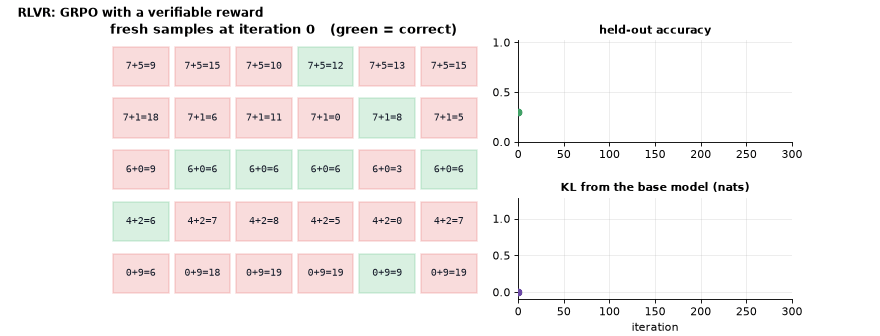

PASS | GRPO with a verifier lifts held-out accuracy far above the base model | 0.29 -> 0.97


In [32]:
torch.manual_seed(51)
grpo_policy = load_base(); grpo_trk = Tracker(ref)
t0 = time.time(); grpo_hist = grpo(grpo_policy, ref, verifier_reward, callback=grpo_trk); print(f"GRPO + verifier: {time.time() - t0:.0f}s")
grpo_acc = float(np.mean([r["acc"] for r in grpo_trk.rows[-5:]]))
print(f"held-out accuracy {acc_te:.2f} -> {grpo_acc:.2f}   (SFT on all 70 demonstrations reached {accuracy(sft70, TEST):.2f}; DPO {dpo_acc:.2f}; PPO with the learned RM {ppo_rm_acc:.2f})")
rl_film(grpo_trk, "pt_grpo_film.gif", "RLVR: GRPO with a verifiable reward", ("kl", "KL from the base model (nats)", COLORS["accent"]))
verify("9 RLVR", "GRPO with a verifier lifts held-out accuracy far above the base model", grpo_acc > acc_te + 0.4, f"{acc_te:.2f} -> {grpo_acc:.2f}")

**Read it.** The tiles flip from red to green with *no demonstrations and no reward model* - only a checker. And it generalises to prompts that were never trained on (the accuracy curve is held-out): RL taught the model to **commit to the answer it already preferred**. Compare the budget with the learned-reward run: same number of samples, much better reward signal.

**The R1 evidence at scale.** The same recipe, with a verifier for competition maths, drove DeepSeek-R1-Zero from 15.6% to 77.9% on AIME (pass@1), with answers growing longer as the model learned to reason:

![R1-Zero training curves](../../assets/rl/course/paper_r1_fig1_aime_length.png)

**DeepSeek-R1 (Guo et al., 2025), Fig. 1 (PDF p. 4):** "(a) AIME accuracy of DeepSeek-R1-Zero during training. [...] (b) The average response length of DeepSeek-R1-Zero on the training set during the RL process." The text on the same page: "the average pass@1 score on AIME 2024 shows a significant increase, jumping from an initial 15.6% to 77.9%."

### 9a. The catch: RL needs *some* signal to start with

GRPO learns from the *difference* between answers in a group. If every answer in a group is wrong, every advantage is **zero** and the gradient vanishes. Starting from a model that is never right, RLVR learns nothing:

untrained model, 100 GRPO iterations: mean reward 0.000, groups with any signal: 0.19%
PASS | an untrained model gets no learning signal: reward stays ~0 


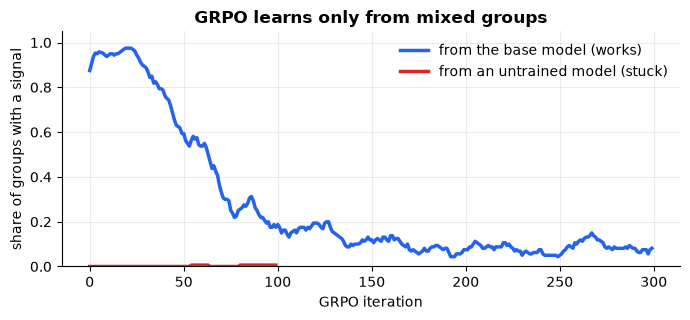

In [33]:
torch.manual_seed(5)
cold = make_policy(tok, seed=5); cold_ref = copy.deepcopy(cold).eval()          # an untrained model: right ~0% of the time
cold_hist = grpo(cold, cold_ref, verifier_reward, iters=100)
print(f"untrained model, 100 GRPO iterations: mean reward {np.mean([h['reward'] for h in cold_hist]):.3f}, groups with any signal: {np.mean([h['informative'] for h in cold_hist]):.2%}")
verify("9 RLVR", "an untrained model gets no learning signal: reward stays ~0", max(h["reward"] for h in cold_hist) < 0.05 and np.mean([h["informative"] for h in cold_hist]) < 0.1)

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.plot(smooth([h["informative"] for h in grpo_hist], 10), color=COLORS["policy"], lw=2.5, label="from the base model (works)")
ax.plot(smooth([h["informative"] for h in cold_hist], 10), color=COLORS["penalty"], lw=2.5, label="from an untrained model (stuck)")
ax.set_ylim(0, 1.05); ax.set_xlabel("GRPO iteration"); ax.set_ylabel("share of groups with a signal"); ax.legend(loc="upper right"); ax.set_title("GRPO learns only from mixed groups")
plt.tight_layout(); plt.show()

That is why real pipelines do **SFT first** (a "cold start"): it lifts the model to the point where RL has something to amplify. Notice the blue curve too: as the model gets *good*, more groups become all-correct and the signal fades - RLVR is self-limiting on easy prompts, which is why practitioners filter for prompts of intermediate difficulty.

### 9b. Critic-based vs critic-free - same verifier, two optimisers

Is GRPO's advantage over the learned-reward run due to the *optimiser* or the *reward*? Run **PPO (with its critic) on the verifier reward** - only the reward changes relative to section 6:

In [34]:
torch.manual_seed(61)
ppo_ver_policy = load_base(); ppo_ver_trk = Tracker(ref)
ppo_ver_hist = ppo_rlhf(ppo_ver_policy, ref, verifier_reward, callback=ppo_ver_trk)
ppo_ver_acc = float(np.mean([r["acc"] for r in ppo_ver_trk.rows[-5:]]))
print(f"PPO + critic + verifier: held-out accuracy {ppo_ver_acc:.2f}   |   GRPO (no critic) + verifier: {grpo_acc:.2f}   |   PPO + learned reward model: {ppo_rm_acc:.2f}")
verify("9 RLVR", "with the SAME verifier, PPO also works - the learned reward model was the bottleneck, not PPO", ppo_ver_acc > ppo_rm_acc + 0.2, f"verifier {ppo_ver_acc:.2f} vs learned RM {ppo_rm_acc:.2f}")

PPO + critic + verifier: held-out accuracy 0.96   |   GRPO (no critic) + verifier: 0.97   |   PPO + learned reward model: 0.59
PASS | with the SAME verifier, PPO also works - the learned reward model was the bottleneck, not PPO | verifier 0.96 vs learned RM 0.59


**Read it.** The reward quality is what separated the runs. GRPO and critic-based PPO land in the same place; GRPO simply gets there **without training or storing a critic** (one network fewer), which is why it dominates large-scale reasoning RL.

### 9c. The usual real recipe: SFT, then RLVR

In [35]:
torch.manual_seed(71)
sft25, _, _ = run_sft(TRAIN[:25], steps=300)
sft25_ref = copy.deepcopy(sft25).eval()
for p_ in sft25_ref.parameters(): p_.requires_grad_(False)
sft25_acc = accuracy(sft25, TEST)
seq_trk = Tracker(sft25_ref, every=25)
grpo(sft25, sft25_ref, verifier_reward, iters=150, callback=seq_trk)
seq_acc = float(np.mean([r["acc"] for r in seq_trk.rows[-3:]]))
print(f"base {acc_te:.2f} -> SFT on 25 demos {sft25_acc:.2f} -> then GRPO with the verifier {seq_acc:.2f}")
verify("9 RLVR", "SFT on a few demonstrations, then RLVR, beats the same SFT alone", seq_acc > sft25_acc + 0.1, f"{sft25_acc:.2f} -> {seq_acc:.2f}")

base 0.29 -> SFT on 25 demos 0.63 -> then GRPO with the verifier 0.86
PASS | SFT on a few demonstrations, then RLVR, beats the same SFT alone | 0.63 -> 0.86


## 10. Head to head, on equal footing

Same base model, same train/test prompts, three seeds each. "Samples" counts the answers the *policy* generated while training; SFT and DPO generate none during training (DPO's pairs cost 8 samples per prompt up front).

In [36]:
def run_seeds(name, fn, seeds=(1, 2, 3)):
    accs = []
    for sd in seeds:
        torch.manual_seed(100 + sd); accs.append(fn(sd))
    print(f"{name:34s} held-out accuracy {np.mean(accs):.2f} +- {np.std(accs):.2f}   {np.round(accs, 2)}")
    return accs

def fit_sft(n, sd):
    m, _, _ = run_sft(TRAIN[:n], steps=300, seed=sd); return accuracy(m, TEST)
def fit_dpo(sd):
    pairs = make_pairs(base_ref, TRAIN * 10, k=8, flip=0.1, seed=sd); pol, _ = train_dpo(pairs, seed=sd); return accuracy(pol, TEST)
def fit_ppo(reward_fn, sd):
    pol = load_base(); ppo_rlhf(pol, ref, reward_fn, seed=sd); return accuracy(pol, TEST)
def fit_grpo(sd):
    pol = load_base(); grpo(pol, ref, verifier_reward, seed=sd); return accuracy(pol, TEST)

RESULTS = {}
RESULTS["SFT, 25 demonstrations"]    = run_seeds("SFT, 25 demonstrations", lambda sd: fit_sft(25, sd))
RESULTS["SFT, 70 demonstrations"]    = run_seeds("SFT, 70 demonstrations", lambda sd: fit_sft(70, sd))
RESULTS["DPO (preference pairs)"]    = run_seeds("DPO (preference pairs)", fit_dpo)
RESULTS["RLHF: PPO + learned RM"]    = run_seeds("RLHF: PPO + learned RM", lambda sd: fit_ppo(rm, sd))
RESULTS["PPO + verifier"]            = run_seeds("PPO + verifier", lambda sd: fit_ppo(verifier_reward, sd))
RESULTS["RLVR: GRPO + verifier"]     = run_seeds("RLVR: GRPO + verifier", fit_grpo)

SFT, 25 demonstrations             held-out accuracy 0.71 +- 0.04   [0.75 0.71 0.66]


SFT, 70 demonstrations             held-out accuracy 0.99 +- 0.01   [1.   1.   0.99]


DPO (preference pairs)             held-out accuracy 0.72 +- 0.12   [0.55 0.84 0.75]


RLHF: PPO + learned RM             held-out accuracy 0.60 +- 0.05   [0.61 0.53 0.64]


PPO + verifier                     held-out accuracy 0.98 +- 0.00   [0.98 0.98 0.98]


RLVR: GRPO + verifier              held-out accuracy 0.96 +- 0.00   [0.96 0.96 0.96]


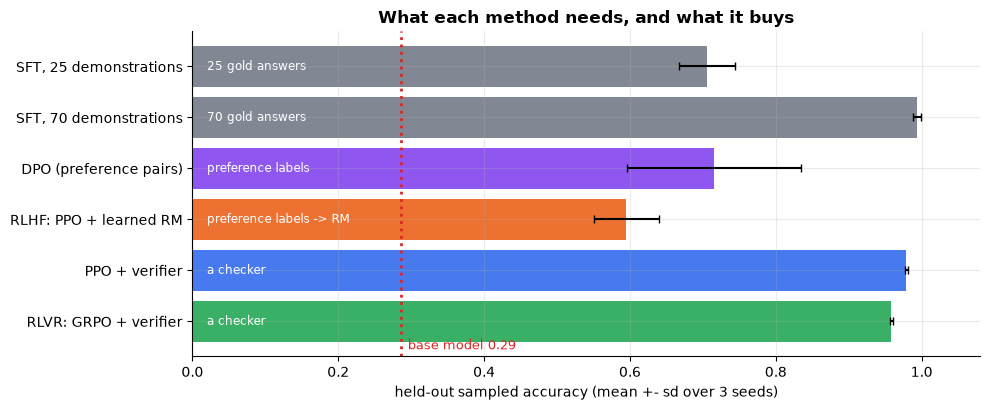

method                     needs                    models in memory               policy samples held-out acc
SFT, 25 demonstrations     25 gold answers          1                              0                0.71 +- 0.04
SFT, 70 demonstrations     70 gold answers          1                              0                0.99 +- 0.01
DPO (preference pairs)     preference labels        2 (policy + frozen ref)        5.6k up front    0.72 +- 0.12
RLHF: PPO + learned RM     preference labels -> RM  4 (policy, ref, RM, critic)    38k              0.60 +- 0.05
PPO + verifier             a checker                3 (policy, ref, critic)        38k              0.98 +- 0.00
RLVR: GRPO + verifier      a checker                2 (policy + frozen ref)        38k              0.96 +- 0.00


In [37]:
needs = {"SFT, 25 demonstrations": ("25 gold answers", "1", "0"), "SFT, 70 demonstrations": ("70 gold answers", "1", "0"),
         "DPO (preference pairs)": ("preference labels", "2 (policy + frozen ref)", "5.6k up front"),
         "RLHF: PPO + learned RM": ("preference labels -> RM", "4 (policy, ref, RM, critic)", "38k"),
         "PPO + verifier": ("a checker", "3 (policy, ref, critic)", "38k"),
         "RLVR: GRPO + verifier": ("a checker", "2 (policy + frozen ref)", "38k")}
palette = [COLORS["reference"], COLORS["reference"], COLORS["accent"], COLORS["value"], COLORS["policy"], COLORS["reward"]]
names = list(RESULTS); means = [np.mean(RESULTS[n]) for n in names]; sds = [np.std(RESULTS[n]) for n in names]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(range(len(names)), means, xerr=sds, color=palette, alpha=0.85, capsize=3)
ax.axvline(acc_te, color=COLORS["penalty"], ls=":", lw=2); ax.text(acc_te + 0.01, len(names) - 0.45, f"base model {acc_te:.2f}", color=COLORS["penalty"], fontsize=9)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.invert_yaxis(); ax.set_xlim(0, 1.08); ax.set_xlabel("held-out sampled accuracy (mean +- sd over 3 seeds)")
for i, n in enumerate(names): ax.text(0.02, i, needs[n][0], va="center", fontsize=8.5, color="white" if means[i] > 0.15 else COLORS["ink"])
ax.set_title("What each method needs, and what it buys"); plt.tight_layout(); plt.show()

print(f"{'method':26s} {'needs':24s} {'models in memory':30s} {'policy samples':14s} {'held-out acc':>12s}")
for n in names: print(f"{n:26s} {needs[n][0]:24s} {needs[n][1]:30s} {needs[n][2]:14s} {np.mean(RESULTS[n]):6.2f} +- {np.std(RESULTS[n]):.2f}")

The *shape* of learning also differs. Online RL methods improve as they collect more of their own samples:

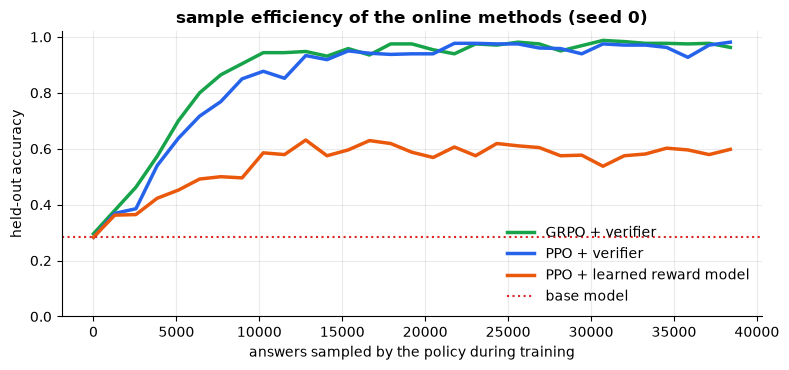

PASS | every method beats the base model | base 0.29; SFT, 25 demo 0.71, SFT, 70 demo 0.99, DPO (prefere 0.72, RLHF 0.60, PPO + verifi 0.98, RLVR 0.96
PASS | more demonstrations help SFT (70 > 25) 
PASS | a verifier is a better reward than the learned reward model on this task (GRPO/PPO+verifier > PPO+RM) 
PASS | RL on the verifier (no gold answers) matches SFT with all 70 gold answers (within 0.08) | GRPO 0.96 vs SFT-70 0.99


In [38]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for trk, lab, col in ((grpo_trk, "GRPO + verifier", COLORS["reward"]), (ppo_ver_trk, "PPO + verifier", COLORS["policy"]), (ppo_rm_trk, "PPO + learned reward model", COLORS["value"])):
    ax.plot([r["it"] * 128 for r in trk.rows], [r["acc"] for r in trk.rows], lw=2.5, color=col, label=lab)
ax.axhline(acc_te, color=COLORS["penalty"], ls=":", label="base model"); ax.set_ylim(0, 1.02)
ax.set_xlabel("answers sampled by the policy during training"); ax.set_ylabel("held-out accuracy"); ax.legend(loc="lower right", bbox_to_anchor=(1.0, 0.0)); ax.set_title("sample efficiency of the online methods (seed 0)")
plt.tight_layout(); plt.show()

m = {n: np.mean(v) for n, v in RESULTS.items()}
verify("10 compare", "every method beats the base model", all(v > acc_te + 0.05 for v in m.values()), f"base {acc_te:.2f}; " + ", ".join(f"{k.split(':')[0][:12]} {v:.2f}" for k, v in m.items()))
verify("10 compare", "more demonstrations help SFT (70 > 25)", m["SFT, 70 demonstrations"] > m["SFT, 25 demonstrations"])
verify("10 compare", "a verifier is a better reward than the learned reward model on this task (GRPO/PPO+verifier > PPO+RM)",
       m["RLVR: GRPO + verifier"] > m["RLHF: PPO + learned RM"] + 0.1 and m["PPO + verifier"] > m["RLHF: PPO + learned RM"] + 0.1)
verify("10 compare", "RL on the verifier (no gold answers) matches SFT with all 70 gold answers (within 0.08)", m["RLVR: GRPO + verifier"] > m["SFT, 70 demonstrations"] - 0.08,
       f"GRPO {m['RLVR: GRPO + verifier']:.2f} vs SFT-70 {m['SFT, 70 demonstrations']:.2f}")

### How do they *fail*? Not just how often

Accuracy hides *what kind* of wrong the model is. Two failure profiles on the 30 held-out prompts (16 samples each): how often the answer is **not even a number**, and on how many prompts the model has become **confidently wrong** (>= 90% of its samples are the *same wrong* answer):

In [39]:
def failure_profile(model, k=16, thr=0.9):
    seq, ok, _ = sample_answers(model, TEST, k)
    answers = [tok.decode(s[P:]) for s in seq.tolist()]
    invalid = float(np.mean([not a.isdigit() for a in answers]))
    confident_wrong = 0
    for i, (p, g) in enumerate(TEST):
        group = answers[i * k:(i + 1) * k]
        top, cnt = max(((a, group.count(a)) for a in set(group)), key=lambda x: x[1])
        confident_wrong += int(cnt / k >= thr and top != g)
    return invalid, confident_wrong

profiles = {"base model": base_ref, "SFT, 70 demonstrations": sft70, "DPO": dpo_policy, "PPO + learned RM": ppo_rm_policy,
            "PPO + verifier": ppo_ver_policy, "GRPO + verifier": grpo_policy}
FAIL = {}
print(f"{'model':24s} {'answers that are not a number':>30s} {'prompts where confidently wrong':>34s}")
for name, mdl in profiles.items():
    torch.manual_seed(7); FAIL[name] = failure_profile(mdl)
    print(f"{name:24s} {FAIL[name][0]:>30.1%} {FAIL[name][1]:>30d} / {len(TEST)}")

model                     answers that are not a number    prompts where confidently wrong
base model                                         0.2%                              0 / 30
SFT, 70 demonstrations                             0.2%                              0 / 30
DPO                                                3.3%                              4 / 30
PPO + learned RM                                   0.2%                              9 / 30
PPO + verifier                                     0.2%                              0 / 30
GRPO + verifier                                    0.2%                              1 / 30


In [40]:
verify("10 failure", "RLHF against the learned reward model leaves the model confidently WRONG on more prompts than RL on the verifier",
       FAIL["PPO + learned RM"][1] >= FAIL["GRPO + verifier"][1] + 3, f"{FAIL['PPO + learned RM'][1]} vs {FAIL['GRPO + verifier'][1]} of {len(TEST)} prompts")
verify("10 failure", "DPO produces malformed (non-numeric) answers more often than any other method",
       FAIL["DPO"][0] > 3 * max(v[0] for k, v in FAIL.items() if k != "DPO") and FAIL["DPO"][0] > 0.01, f"DPO {FAIL['DPO'][0]:.1%} vs next {max(v[0] for k, v in FAIL.items() if k != 'DPO'):.1%}")

PASS | RLHF against the learned reward model leaves the model confidently WRONG on more prompts than RL on the verifier | 9 vs 1 of 30 prompts
PASS | DPO produces malformed (non-numeric) answers more often than any other method | DPO 3.3% vs next 0.2%


**Two different failures, two different causes.**

- **PPO against the learned reward model** collapsed onto *one* answer per prompt - and for a good share of prompts it is a *wrong* one. This is §4's loophole made visible: a strong optimiser finds answers the judge loves and commits to them.
- **DPO** is the only method that sometimes emits something that is not even a number (a stray letter in the answer). It optimises a *gap*: making rejected answers less likely frees probability mass, and nothing in the loss says where that mass must go - including tokens that appear in no training data.
- **Verifier-based RL** (PPO or GRPO) and SFT stay clean: the checker rewards only answers that are exactly right, so there is no loophole to find.

**How to read this honestly.**

- **SFT on all 70 gold answers is the strongest method here (about 0.99)** - and it is the simplest and cheapest. Do not let the RL machinery fool you: *if you have a correct answer for every prompt and the model already contains the skill, imitation is very hard to beat.* Our toy is exactly that case (the base model already "knows" arithmetic).
- What RLVR buys is that it reaches nearly the same place with **no gold answers at all - only a checker** - and the SFT-25 row shows what happens when demonstrations are scarce (0.71).
- In real reasoning problems, demonstrations cannot cover the space, and SFT can never exceed its demonstrators, while RL on a checker can discover new strategies. A one-digit-sum toy cannot show that regime; the R1 curves in section 9 are the evidence for it.
- **Learned rewards are the weak link:** PPO+RM and DPO (both fed by preference labels) trail the verifier methods, and DPO has by far the largest seed-to-seed spread.

## 11. Pitfalls - each one you have now seen

| pitfall | where you saw it | the fix in practice |
|---|---|---|
| **Reward hacking / over-optimisation** of a learned reward | §6: reward-model score kept rising while true accuracy saturated | stronger/ensembled reward models, KL leash, early stopping, verifiable rewards where possible |
| **KL leash too loose / too tight** | §6: smaller $\beta$ drifted further from the base model | tune $\beta$; watch KL during training |
| **No signal at the start** | §9a: untrained model, zero-advantage groups | SFT cold start; curriculum of prompts the model sometimes solves |
| **Signal fades when the task is mastered** | §9a: share of informative groups falls | filter out too-easy prompts; harder data |
| **Offline data goes stale** (DPO) | §7: pairs come from the base model only | iterate: re-sample and re-label (online/iterative DPO) |
| **Noisy preferences** | 10% flipped labels in §4 | more data, cleaner labelling, noise-robust losses |

### Cheat sheet: which one when?

```mermaid
flowchart TD
    Q1{"Do you have an automatic checker<br/>(maths, code, format)?"} -- yes --> RLVR["RLVR: GRPO (or PPO) on the checker<br/>after an SFT cold start"]
    Q1 -- no --> Q2{"Do you have preference<br/>comparisons?"}
    Q2 -- yes --> Q3{"Need to keep optimising on the<br/>model's OWN new outputs?"}
    Q3 -- "no, keep it simple" --> DPO["DPO"]
    Q3 -- yes --> RLHF["Reward model + PPO (RLHF)"]
    Q2 -- no --> SFT["SFT on demonstrations"]
```

## 12. Recap

1. An LLM is a **policy**; training it means changing next-token probabilities. `generate` samples, `sequence_logprobs` scores.
2. **SFT** imitates demonstrations: simple, stable, but needs the right answer and only teaches what to copy.
3. A **reward** can be learned from preferences (Bradley-Terry) or computed by a **verifier**.
4. **RLHF/PPO** maximises reward minus a KL leash with four models; against a learned reward it over-optimises.
5. **DPO** uses the closed-form RLHF optimum to turn preferences into one supervised loss - no reward model, no RL loop.
6. **GRPO** replaces PPO's critic with a group baseline; with a verifier that is **RLVR**.
7. Real pipelines chain them: **SFT -> (DPO) -> RLVR** (Tülu 3's recipe).

### Exercises
- Change `p_correct` in `noisy_answer` to 0.05 (a much worse base model). Does GRPO still work from the base model? Which section predicts the answer?
- In `ppo_rlhf`, set `lam=0` and then `lam=1`. How does learning change?
- Run DPO with `flip=0.4` (very noisy labels). How does the reward model's AUC behave with the same noise?
- Make the verifier *partial credit* (reward the number of correct digits). Does RL learn faster? Could it also be hacked?

### Honest limits
A 2-layer GPT answering one-digit sums is a *microscope*, not a benchmark: it shows the mechanics and the relative behaviour of the methods, not their absolute performance at scale. The verifier here is perfect and the task is easy to check, which flatters RLVR; the preference labeler here is a noisy checker, not a human with taste, which the real RLHF settings add to. Numbers are means over three seeds and will move a little between machines.

## Verification table

In [41]:
print(f"{'section':12s} {'status':6s} claim")
for section, claim, ok, detail in VERIFIED:
    print(f"{section:12s} {'PASS' if ok else 'FAIL':6s} {claim}")
print(f"\n{sum(v[2] for v in VERIFIED)} of {len(VERIFIED)} checks passed")
assert all(v[2] for v in VERIFIED)

section      status claim
1 policy     PASS   teacher-forced log-prob equals the token-by-token chain rule
2 base       PASS   the base model is wrong most of the time when sampled (< 45%)
2 base       PASS   ...yet its most likely answer is often right (greedy > sampled + 0.2)
3 SFT        PASS   SFT loss = -mean log pi(answer tokens | prompt), prompt excluded
3 SFT        PASS   SFT improves over the base model and more demonstrations help
4 RM         PASS   tie (r_w = r_l) costs exactly log 2
4 RM         PASS   a confident correct ranking is nearly free; a confident wrong one is expensive
4 RM         PASS   the reward model ranks correct above wrong answers on unseen prompts (AUC > 0.65)
4 RM         PASS   ...yet some wrong answers get top marks (loopholes exist)
4 RM         PASS   ...but it is far from a perfect judge (AUC < 0.97) - keep this in mind for section 6
4 verifier   PASS   the verifier agrees with the task's own exact-match reward
5 PG         PASS   the policy-grad

## Appendix: learning rates (why those values)

The learning rates above (GRPO `3e-4`; PPO `1e-4`) were chosen from `{1e-4, 3e-4}` on a first pass. Here is the sweep so the choice is not hidden (seed 0, 150 iterations, held-out accuracy). Read it as: GRPO prefers the larger rate, PPO with the learned reward model the smaller, and PPO with the verifier is nearly indifferent:

In [42]:
sweep = {}
for lr in (1e-4, 3e-4):
    torch.manual_seed(7); pol = load_base(); grpo(pol, ref, verifier_reward, lr=lr, iters=150); g = accuracy(pol, TEST)
    torch.manual_seed(7); pol = load_base(); ppo_rlhf(pol, ref, verifier_reward, lr=lr, iters=150); pv = accuracy(pol, TEST)
    torch.manual_seed(7); pol = load_base(); ppo_rlhf(pol, ref, rm, lr=lr, iters=150); pr = accuracy(pol, TEST)
    sweep[lr] = (g, pv, pr); print(f"lr {lr:.0e} | GRPO+verifier {g:.2f} | PPO+verifier {pv:.2f} | PPO+RM {pr:.2f}   (150 iterations each)")

lr 1e-04 | GRPO+verifier 0.87 | PPO+verifier 0.94 | PPO+RM 0.65   (150 iterations each)


lr 3e-04 | GRPO+verifier 0.95 | PPO+verifier 0.96 | PPO+RM 0.56   (150 iterations each)
